# F03.04 · La primera red neuronal: ¿aprende una red lo que vio XGBoost en el último minuto?

![Portada del notebook F03.04](img/portada_notebook_04.png)

> 🧭 **En 30 segundos**
> - **Para qué:** construir y entrenar la **primera red neuronal** de predicción (⏳ preictal frente a 💤 interictal) con lo que decidió F03.03: **60 s de contexto** y **cada paciente comparado consigo mismo**.
> - **Entra:** las ventanas de **F03.01**, la señal de **F02.02** (para leer el contexto), la decisión de **F03.03** y sus puntuaciones (para comparar) → **Sale:** tres redes entrenadas (con 60 s, con 4 s y con el mismo peso por paciente), su nota en 🟡 dev **ventana a ventana frente a XGBoost**, por paciente, por grupo de crisis y en el control de sesión, y los modelos guardados.
> - **Idea clave:** la red es **CNN + GRU**. La CNN resume cada ventana de 4 s; la GRU lee las 15 ventanas del último minuto **en orden**. A diferencia de XGBoost, que solo veía un resumen (media, variación, cambio), la red puede ver **cómo evoluciona** el minuto.

> 📍 **Dónde estamos: Fase 3 · notebook 4 (F03.04).** F03.02 dejó la línea base (≈ azar con la ventana sola). F03.03 vio que mirar 60 s atrás **y** comparar a cada paciente consigo mismo sí separa ⏳ de 💤 con XGBoost. Esa es la nota que tiene que superar la red.

> 🔄 **Es dinámico.** Lee lo que dejaron F03.01, F03.02 y F03.03; las cifras, las comparaciones y las conclusiones salen de los datos al ejecutarlo.

> 🔒 **Regla de oro de la Fase 3: aquí no se mira 🟢 eval.** Todo se decide con 🟡 dev.

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| Fase 2 | Preprocesado y ventanas | ✅ terminada |
| **Fase 3** | **Modelo de predicción (⏳ preictal frente a 💤 interictal)** | 👉 **en curso** (la fase de este notebook) |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

## 🧩 La idea, en sencillo

Siguiendo con el ejemplo del médico y la tensión arterial de F03.03:

1. **XGBoost (F03.03)** recibía un **resumen** del último minuto: "la media de la tensión fue 13, se movió poco y la de ahora es algo más alta". Con eso ya separa algo ⏳ de 💤.
2. **La red** recibe las **15 medidas en orden**, cada una completa (el espectro entero, no 5 bandas), y aprende **ella sola** qué mirar: puede notar "empezó a subir hace 30 s y no ha parado", que un resumen no ve.
3. Lo que **no cambia**: cada paciente se compara consigo mismo (su "normal" sale de sus momentos tranquilos), igual que en F03.03.

Este notebook responde a cuatro preguntas:

| Pregunta | Dónde se responde |
|---|---|
| ¿La red supera a XGBoost de F03.03 con las mismas ventanas? | §8 y §9 (recuadro dorado) |
| ¿Le sirve a la red mirar 60 s, o le basta la ventana actual? | §9 (red de 60 s frente a red de 4 s) |
| ¿Acierta en la mayoría de pacientes o solo en unos pocos? ¿Y en cada grupo de crisis? | §10 |
| ¿Predice la crisis o reconoce la grabación? | §11 (control de sesión) |

## El recorrido de este notebook

![El recorrido del notebook F03.04](img/mapa_notebook_04.png)

👀 **Qué enseña.** Los seis pasos, en orden. Los dos en rojo son los importantes: **entrenar** las redes (§7) y **compararlas** con XGBoost de F03.03 con las mismas ventanas (§8-§11). Abajo, contra qué se compara siempre.

### 📖 Diccionario rápido

| Término | Qué significa, en sencillo |
|---|---|
| **Red neuronal** | Una función con muchos números ajustables (**pesos**) que se van corrigiendo con los ejemplos hasta que acierta. Esta tiene unos 50.000 |
| **CNN** (red convolucional) | Capas que pasan un **filtro** pequeño a lo largo de un eje (aquí, la frecuencia) buscando formas: "un pico en 8-12 Hz", "mucha energía lenta". Ver §6 |
| **GRU** (*Gated Recurrent Unit*) | Una capa que lee una **secuencia en orden** con una **memoria**; en cada paso decide con dos "puertas" qué conserva y qué reescribe. Ver §6 |
| **Espectro relativo** | Qué parte de la energía de un canal cae en cada frecuencia (de 1 a 40 Hz). Lo que ve la red de cada ventana. Ver §4 |
| **Época** | Una pasada completa por todos los datos de entrenamiento |
| **Pérdida** (*loss*) | El número que mide cuánto se equivoca la red al entrenar; lo que el entrenamiento intenta bajar |
| **Parada temprana** | Quedarse con la red de la época que mejor nota saca en 🟡 dev y parar cuando deja de mejorar. Ver §7 |
| **Sobreajuste** | Aprenderse los ejemplos (aquí, los pacientes de train) en vez de la regla general: mejora en train y empeora en dev |
| **Semilla** | El número que fija el azar (pesos iniciales, orden de los lotes). Con otra semilla la misma red sale algo distinta; por eso se entrenan **tres** y se promedian |
| **Diferencia emparejada** | Comparar dos modelos con las mismas ventanas y los mismos sorteos de pacientes: su intervalo dice si una mejora es real (F03.03 §9) |
| **AUC-ROC** | La nota: 0,5 = azar, 1 = perfecto (F03.02 §5) |

## 0. Los parámetros

> 🎯 **Qué hacemos:** elegir el conjunto y si se hace una prueba rápida.
>
> 🤔 **Por qué:** el conjunto tiene que ser el de F03.01-F03.03; la prueba rápida comprueba que todo funciona antes de entrenar de verdad.

- `CONJUNTO`: `general` es el modelo principal. Para las ausencias, `grupo_ausencia` (antes hay que ejecutar F03.01, F03.02 y F03.03 con ese conjunto).
- `MODO_PRUEBA`: `True` para comprobar que todo funciona en pocos minutos (un 10 % de las ventanas, 1 semilla, 2 épocas). Las cifras no valen; los ficheros se guardan con `_prueba`.

*(La celda lleva la etiqueta `parameters` para poder lanzarla con papermill cambiando solo estos valores.)*

> **`CONJUNTO` se fija en un solo sitio para toda la Fase 3:** `tfm_comun/prediccion/estudio.py` (`CONJUNTO_ESTUDIO`). Aquí se deja en `None`; solo se pone otro valor para una prueba puntual (o desde papermill). Los resultados de cada conjunto van a su carpeta: `outputs/fase_03/<conjunto>/`.

In [1]:
CONJUNTO = None   # None = el de tfm_comun/prediccion/estudio.py (el mismo en toda la Fase 3); se puede poner otro aquí
MODO_PRUEBA = False

## 1. Librerías

> 🎯 **Qué hacemos:** comprobar que están instaladas las librerías (las de la línea base + **PyTorch**, con CUDA si hay tarjeta NVIDIA).

In [2]:
# Requisitos: se comprueba (e instala si falta) lo que necesita el notebook ANTES de importar nada más
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
from tfm_comun.entorno.requisitos import comprobar_requisitos, REQUISITOS_FASE_03_RED
disponibles = comprobar_requisitos(REQUISITOS_FASE_03_RED)

,estado,versión,para qué
librería,,,
numpy,✅,2.5.4,cálculo con matrices
pandas,✅,3.0.6,tablas
matplotlib,✅,3.11.2,figuras
scipy,✅,1.18.1,espectro de cada ventana (Welch)
scikit-learn,✅,1.9.1,"regresión logística, AUROC y curvas ROC"
xgboost,✅,3.4.1,XGBoost: árboles de decisión encadenados
joblib,✅,1.6.0,guardar los modelos entrenados
tqdm,✅,4.70.1,barra de progreso al calcular las características
torch,✅,2.15.0+cu132,"la red neuronal: capas, entrenamiento en la GPU (PyTorch)"


Todo lo necesario está instalado.


In [ ]:
# 1) Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

# 2) Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado), sin reiniciar el kernel
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

# 3) Librerías de siempre
import json
from functools import partial
import re
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import torch
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score, roc_curve
from tqdm.auto import tqdm
from IPython.display import display, Markdown

# 4) tfm_comun: entorno, señal, red y entrenamiento
from tfm_comun.entorno.rutas import RUTA_OUTPUTS_FASE_03, RUTA_SENALES, carpeta_resultados
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.entorno.dispositivo import elegir_dispositivo
from tfm_comun.entorno.configuracion import leer_configuracion
from tfm_comun.entorno.nombres_fichero import nombre_fichero
from tfm_comun.senal.bandas import BANDAS_HZ
from tfm_comun.senal.montaje import CANALES_TCP
from tfm_comun.red.paquetes import cargar_paquete
from tfm_comun.red.reproducibilidad import fijar_semillas
from tfm_comun.red.entradas.espectro_relativo import espectro_relativo
from tfm_comun.red.entradas.rango_frecuencias import frecuencias_entrada
from tfm_comun.red.lotes.secuencias_espectro import SecuenciasEspectro
from tfm_comun.red.lotes.orden_epoca import peso_por_paciente
from tfm_comun.red.redes.cnn_gru import ARQUITECTURA
from tfm_comun.red.modelo import crear_red, contar_parametros
from tfm_comun.red.entreno.entrenar_red import ENTRENAMIENTO, entrenar_red
from tfm_comun.red.entreno.puntuacion import puntuar_red
from tfm_comun.red.entreno.parada_interna import separar_parada

# 5) tfm_comun: características, contexto, normalización y evaluación
from tfm_comun.prediccion.almacen_caracteristicas import caracteristicas_al_dia, guardar_caracteristicas, cargar_caracteristicas
from tfm_comun.prediccion.contextos.duracion import ventanas_por_contexto
from tfm_comun.prediccion.contextos.disponibilidad import con_contexto_completo, inicios_necesarios, clave
from tfm_comun.prediccion.contextos.calculo import caracteristicas_de_inicios
from tfm_comun.prediccion.contextos.indices import indices_contexto
from tfm_comun.prediccion.normalizacion_paciente import NORMALIZACIONES_RED, calibracion_para_red, ventanas_del_estudio
from tfm_comun.prediccion.atajo_grabacion import (CONTROL_ESTRICTO, NOMBRE_CARPETA_03B, controles_estrictos, leer_decision_red,
                                                  mascara_montaje, mascara_muestreo, posicion_respecto_crisis)
from tfm_comun.prediccion.validacion import rondas_validacion
from tfm_comun.prediccion.evaluacion.auroc_global import auroc_con_intervalo, diferencia_auroc_con_intervalo
from tfm_comun.prediccion.evaluacion.auroc_paciente import auroc_por_paciente
from tfm_comun.prediccion.evaluacion.sensibilidad import sensibilidad_con_especificidad
from tfm_comun.prediccion.control_sesion import controles_de_sesion
from tfm_comun.prediccion.evaluacion.lectura import lectura_diferencia

# 6) tfm_comun: cómo se enseñan las cosas (iconos, colores, números, tablas, ficheros, letra)
from tfm_comun.visual.iconos import con_icono
from tfm_comun.visual.colores import COLORES_PERIODO, COLORES_ESQUEMA
from tfm_comun.visual.numeros import numero_legible, decimal, con_intervalo, con_signo
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.visual.ficheros import mostrar_fichero
from tfm_comun.visual.tipografia import ESTILO_TIMES

In [4]:
# 1) Versiones de las librerías
versiones_usadas = mostrar_versiones(np, pd, matplotlib, scipy, sklearn, torch)

# 2) El conjunto: si la celda de parámetros lo deja en None, el de tfm_comun/prediccion/estudio.py
from tfm_comun.prediccion.estudio import conjunto_del_estudio
CONJUNTO = conjunto_del_estudio(CONJUNTO)

Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
scipy       1.18.1
sklearn     1.9.1
torch       2.15.0+cu132


✅ **Qué deberías ver:** en la tabla de librerías, todas con ✅ (o 🆕 si se acaban de instalar), y debajo la versión de cada una.

## 2. Configuración

> 🎯 **Qué hacemos:** fijar los "botones" del notebook, leer lo que dejaron F03.01, F03.02 y F03.03 y elegir dónde se entrena (GPU o procesador).
>
> 🤔 **Por qué:** el **contexto**, la **normalización** y el **muestreo** no se eligen aquí: los decidió **F03.03b** (el atajo de la grabación) si se ejecutó, y si no **F03.03** (`decision_red` de su `configuracion.json`; lo lee `leer_decision_red`). Así la red se compara con XGBoost en igualdad de condiciones: misma información, mismas ventanas; solo cambia el modelo.

| Parámetro | Valor | Qué controla |
|---|---|---|
| `VARIANTES` | 3 redes | **principal**: el contexto que decidió F03.03 · **sin contexto**: la misma red con solo la ventana actual (4 s), para medir si la red aprovecha el minuto · **mismo peso por paciente**: la principal, pero en cada época cada paciente sale las mismas veces (`WeightedRandomSampler`), como la variante de la línea base |
| `N_SEMILLAS` | 3 | Cada red se entrena 3 veces con distinta semilla y se **promedian** sus puntuaciones: la nota no depende de la suerte de una semilla, y se ve cuánto varía |
| `ARQUITECTURA` | `tfm_comun/red/redes/cnn_gru.py` | 32 filtros, resumen de 64 números por ventana, memoria de la GRU de 64, dropout 0,3 (§6) |
| `ENTRENAMIENTO` | `tfm_comun/red/entreno/entrenar_red.py` | Hasta 40 épocas, paciencia 6, lotes de 128, tasa de aprendizaje 0,001, weight decay 0,01, reflejo de hemisferios en el 50 % (§7) |
| `FRACCION_PARADA` | 0,2 | Parte de los pacientes de 🔵 train (con ⏳ y 💤) que se apartan **solo para decidir cuándo parar** (§7). Así 🟡 dev no influye en el entrenamiento y su AUC es limpia. `0` = la parada antigua, con 🟡 dev (optimista) |
| `ESPECIFICIDAD` | 0,9 | Como en F03.02 y F03.03 |
| `N_BOOTSTRAP` | 500 | Sorteos de pacientes para los intervalos |
| `MEJORA_MINIMA` | 0,02 | Como en F03.03: por debajo, una mejora no compensa la complejidad de la red aunque sea "real" |

In [ ]:
N_SEMILLAS = 3
FRACCION_PARADA = 0.2   # pacientes de train apartados para la parada temprana (0 = parar con 🟡 dev, optimista)
ESPECIFICIDAD = 0.9
N_BOOTSTRAP = 500
MEJORA_MINIMA = 0.02

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code> · <code>True</code> = prueba rápida (pocas ventanas, 1 semilla); las cifras no valen <i style="color:#4d4d4d">(§0)</i></li></ul></div>

In [ ]:
# 1) Carpetas de resultados, figuras y modelos (con sufijo _prueba en modo prueba)
SUFIJO = '_prueba' if MODO_PRUEBA else ''
RUTA_RESULTADOS, RUTA_FIGURAS = carpeta_resultados(f'fase_03/{CONJUNTO}/04_red_prediccion' + SUFIJO)
RUTA_MODELOS = RUTA_RESULTADOS / 'modelos'
RUTA_MODELOS.mkdir(exist_ok=True)

# 2) leer_config: el configuracion.json de un notebook anterior, comprobando que es de este CONJUNTO
# (tfm_comun/entorno/configuracion.py; para con un mensaje claro si falta o es de otro conjunto)
leer_config = partial(leer_configuracion, conjunto=CONJUNTO)
config_01 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '01_datos_red' / 'configuracion.json', 'F03.01 (fase_03/01_datos_red.ipynb)')
config_02 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '02_linea_base' / 'configuracion.json', 'F03.02 (fase_03/02_linea_base.ipynb)')
config_03 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '03_contexto_y_paciente' / 'configuracion.json', 'F03.03 (fase_03/03_contexto_y_paciente.ipynb)')

# 3) Las cifras que mandan F03.01 y F03.03 (no se copian a mano)
SEMILLA = int(config_01['semilla'])
VENTANA_S = config_01['ventana_s']
MUESTRAS = int(config_01['muestras_por_ventana'])
FS = MUESTRAS / VENTANA_S
SPLITS = [s for s in ['train', 'dev'] if s in config_01['paquetes']]          # 🟢 eval NO se usa aquí
DECISION = leer_decision_red(CONJUNTO, config_03)                               # la de F03.03b si existe; si no, la de F03.03
CONTEXTO_S, NORMALIZACION, MUESTREO = DECISION['contexto_s'], DECISION['normalizacion'], DECISION['muestreo']
MONTAJE_E = DECISION['montaje_entrenamiento']                                    # con qué montajes originales se entrena
config_ref = DECISION['config_03b'] or config_03                                  # el notebook que decidió (y fijó las ventanas)
RUTA_REFERENCIA = RUTA_OUTPUTS_FASE_03 / CONJUNTO / (NOMBRE_CARPETA_03B if DECISION['origen'] == 'F03.03b' else '03_contexto_y_paciente')
assert NORMALIZACION in NORMALIZACIONES_RED, (f'🔴 {DECISION["origen"]} pide la normalización {NORMALIZACION!r}, que la red no conoce '
                                             f'(opciones: {NORMALIZACIONES_RED}). ¿Es un configuracion.json antiguo? Vuelve a ejecutarlo.')
RESERVA = config_03.get('reserva_calibracion')
assert RESERVA, '🔴 El configuracion.json de F03.03 no tiene reserva_calibracion: vuelve a ejecutar F03.03.'
K_RED = ventanas_por_contexto(CONTEXTO_S, VENTANA_S)                           # ventanas de 4 s que ve la red (15 con 60 s)
K_MAX = ventanas_por_contexto(max(config_03['contextos_s']), VENTANA_S)       # las MISMAS ventanas que F03.03

# 4) La nota que hay que superar: el XGBoost del notebook que decidió (F03.03b o F03.03)
AUC_XGB = config_ref['mejor']['auc_dev']
NOMBRE_XGB = (f'XGBoost {DECISION["origen"]} ({config_ref["mejor"]["contexto_s"]} s, {config_ref["mejor"]["normalizacion"]}'
              + (f', muestreo {config_ref["mejor"]["muestreo"]}' if 'muestreo' in config_ref['mejor'] else '')
              + (f', montaje {config_ref["mejor"]["montaje_entrenamiento"]}' if 'montaje_entrenamiento' in config_ref['mejor'] else '') + ')')
NOMBRE_BASE = 'línea base F03.02 (XGBoost, 4 s)'

# 5) ¿Recibe la red la MISMA información que el XGBoost con el que se compara? Si no, la comparación justa es otra
MISMA_INFORMACION = (CONTEXTO_S == int(config_ref['mejor']['contexto_s']) and NORMALIZACION == config_ref['mejor']['normalizacion']
                     and MUESTREO == config_ref['mejor'].get('muestreo', 'todas')
                     and MONTAJE_E == config_ref['mejor'].get('montaje_entrenamiento', 'todos'))
REFERENCIA_JUSTA = (NOMBRE_XGB if MISMA_INFORMACION else
                    NOMBRE_BASE if (CONTEXTO_S == min(config_03['contextos_s']) and NORMALIZACION == 'ninguna' and MUESTREO == 'todas'
                                    and MONTAJE_E == 'todos') else None)

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code> · <code>True</code> = prueba rápida (pocas ventanas, 1 semilla); las cifras no valen <i style="color:#4d4d4d">(§0)</i></li></ul></div>

In [ ]:
# 1) Las variantes de la red: principal, sin contexto y mismo peso por paciente
PRINCIPAL = f'red_{CONTEXTO_S}s'
VARIANTES = {PRINCIPAL: {'k': K_RED, 'mismo_peso': False,
                         'qué es': f'la red principal: {CONTEXTO_S} s de contexto ({K_RED} ventanas), la decisión de {DECISION["origen"]}'}}
if K_RED > 1:
    VARIANTES[f'red_{VENTANA_S}s'] = {'k': 1, 'mismo_peso': False,
                                      'qué es': f'la misma red con solo la ventana actual ({VENTANA_S} s): ¿la red aprovecha el contexto?'}
VARIANTES[f'{PRINCIPAL}_mismo_peso'] = {'k': K_RED, 'mismo_peso': True,
                                        'qué es': 'la principal, pero cada paciente sale las mismas veces en cada época'}
SIN_CONTEXTO = f'red_{VENTANA_S}s' if K_RED > 1 else None
MISMO_PESO = f'{PRINCIPAL}_mismo_peso'

# 2) Ajustes de entrenamiento (en modo prueba, 1 semilla y 2 épocas)
AJUSTES = dict(ENTRENAMIENTO)
if MODO_PRUEBA:
    N_SEMILLAS, AJUSTES['epocas_max'] = 1, 2

# 3) Dónde se entrena (GPU o procesador)
dispositivo, ficha = elegir_dispositivo()

# 4) Tabla de variantes y resumen
tabla_variantes = pd.DataFrame({n: {'ventanas que ve': v['k'], 'segundos': v['k'] * VENTANA_S,
                                    'mismo peso por paciente': 'sí' if v['mismo_peso'] else 'no', 'qué es': v['qué es']}
                                for n, v in VARIANTES.items()}).T
tabla_variantes.index.name = 'variante'
display(con_separadores(tabla_variantes, decimales=0))
print(f'Conjunto: {CONJUNTO}{" · 🔴 MODO PRUEBA (cifras sin valor)" if MODO_PRUEBA else ""} · decisión de {DECISION["origen"]}: {DECISION["texto"]} '
      f'({CONTEXTO_S} s, {NORMALIZACION}, muestreo {MUESTREO}, montaje de entrenamiento {MONTAJE_E})')
if DECISION['origen'] == 'F03.03':
    print('🟡 F03.03b (el atajo de la grabación) no se ha ejecutado: la red se entrena con todas las 💤 y puede aprender la grabación.')
print(f'Dispositivo: {ficha["dispositivo"]} · {ficha["nombre"]}' + (f' · {ficha["memoria (GB)"]} GB' if ficha['memoria (GB)'] else '')
      + (f'\n{ficha["aviso"]}' if ficha['aviso'] else ''))
print(f'A superar en 🟡 dev: {NOMBRE_XGB} → AUC {decimal(AUC_XGB)}  ·  🟢 eval no se abre en este notebook')
if not MISMA_INFORMACION:
    print(f'🟡 Ojo: la red recibe {CONTEXTO_S} s y normalización {NORMALIZACION}, pero {NOMBRE_XGB} tuvo más información. '
          'Compararlos mezcla dos cosas (el modelo y lo que ve). '
          + (f'La comparación justa (misma información) es frente a la {NOMBRE_BASE}: se añade en §9.' if REFERENCIA_JUSTA else
             'No hay un XGBoost guardado con la misma información: §9 lo indica.'))

### 🔙 De dónde venimos

![La historia de la Fase 3, con F03.04 destacado](img/historia_fase_03_nb04.png)

👀 **Qué enseña.** El recuadro rojo marca **dónde estás**; el resto de la fase sale atenuado. Las preguntas de la fase y lo que salió en cada notebook. Las cifras de abajo se leen de sus resultados:

In [8]:
# 1) El veredicto del control de sesión de F03.03
control_03 = config_03.get('control_sesion')
control_03 = (control_03.get('veredicto', str(control_03)) if isinstance(control_03, dict) else
              str(control_03) if control_03 else '— (no está en su configuracion.json: vuelve a ejecutar F03.03 entero)')

# 2) Lo que salió en F03.02 y F03.03, con su nota
historia = pd.DataFrame([
    ('F03.02 · XGBoost, ventana de 4 s sola', decimal(config_02['referencia']['auc_dev']),
     'casi el azar: a la ventana suelta le falta información' if config_02['referencia']['ic95_dev'][0] <= 0.5 else 'algo por encima del azar'),
    ('F03.02 · detectar la crisis con los mismos números', decimal(config_02.get('comprobacion_deteccion', {}).get('auc_dev', float('nan'))),
     'la cadena de datos funciona'),
    (f'F03.03 · {NOMBRE_XGB}', con_intervalo(AUC_XGB, *config_03['mejor']['ic95_dev']),
     f'{con_signo(config_03["mejor"]["diferencia_con_4s"])} sobre la ventana sola: ' + ('mejora real' if config_03['mejor']['ic95_diferencia'][0] > 0 else 'puede ser casualidad')),
    ('F03.03 · control de sesión', control_03, ''),
], columns=['qué se probó', 'AUC en 🟡 dev', 'lectura']).set_index('qué se probó')

# 3) Mostrarlo destacado
mostrar_destacado('Lo que hereda la red', f'<b>{DECISION["texto"]}.</b> La red tiene que superar a XGBoost de F03.03 '
                  'con <b>las mismas ventanas</b>; si no lo supera, una red no compensa (todavía).', historia)

,AUC en 🟡 dev,lectura
qué se probó,,
"F03.02 · XGBoost, ventana de 4 s sola","0,52",casi el azar: a la ventana suelta le falta información
F03.02 · detectar la crisis con los mismos números,"0,79",la cadena de datos funciona
"F03.03 · XGBoost F03.03 (16 s, por_paciente)","0,57 [0,47 – 0,63]","+0,112 sobre la ventana sola: puede ser casualidad"
F03.03 · control de sesión,🔴 Se cae: reconocía la grabación,


## 3. Qué ventanas: las mismas que F03.03

> 🎯 **Qué hacemos:** quedarnos con las ventanas de F03.01 que tienen detrás, dentro de su tramo, el **contexto más largo** que probó F03.03.
>
> 🤔 **Por qué:** así son **exactamente las mismas** ventanas con las que se midió XGBoost, y la comparación de §8-§9 es ventana a ventana. La red de 4 s (sin contexto) también se mide con ellas.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">K_MAX</code> · ventanas de 4 s del contexto más largo <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code> · <code>True</code> = prueba rápida (pocas ventanas, 1 semilla); las cifras no valen <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MUESTRAS</code> · muestras de una ventana de 4 s <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code> · semilla común (F03.01) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SPLITS</code> · particiones que se usan aquí (🔵 train y 🟡 dev) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">config_03</code> · configuración de F03.03 (la decisión para la red) <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [ ]:
# 1) Juntar los índices de 🔵 train y 🟡 dev y quedarse con las ventanas con contexto completo
partes = []
for split in SPLITS:
    _, indice = cargar_paquete(CONJUNTO, split)
    partes.append(indice)
todas = pd.concat(partes, ignore_index=True)
completo = con_contexto_completo(todas, K_MAX, MUESTRAS)
if MODO_PRUEBA:                                    # un 10 % de las filas, al azar (solo para comprobar que todo funciona)
    completo &= np.random.default_rng(SEMILLA).random(len(todas)) < 0.1
filas_todas = todas[completo].reset_index(drop=True)

# 2) Las ventanas de la decisión, calculadas igual que en F03.03 (§6) y F03.03b (§3): sin las 💤 reservadas para calibrar
#    (por paciente y, si decidió F03.03b, también por sesión) ni las de pacientes o sesiones que no se pueden calibrar
reservada_todas, usar, grupos_todas = ventanas_del_estudio(filas_todas, FS, VENTANA_S, RESERVA, NORMALIZACION, DECISION['reserva_por_sesion'])
fuera_todas = ~usar & ~reservada_todas                                         # apartadas por otra razón (sin calibración, reserva por sesión)

# 3) Tabla: cuántas se quedan por partición y clase
en_todas = lambda mascara: pd.Series(mascara, index=np.where(completo)[0]).reindex(range(len(todas)), fill_value=False).to_numpy()
completo_r, usar_r = completo, en_todas(usar)
reservada_r, fuera_r = en_todas(reservada_todas), en_todas(fuera_todas)
filas_tabla = {}
for (split, clase), t in todas.groupby(['split', 'clase'], sort=False):
    i = t.index.to_numpy()
    filas_tabla[(con_icono(split), con_icono(clase))] = {'ventanas en F03.01': len(i), 'con contexto completo': int(completo_r[i].sum()),
                                                         'reservadas para calibrar': int(reservada_r[i].sum()),
                                                         'otras apartadas': int(fuera_r[i].sum()),
                                                         'las que se usan': int(usar_r[i].sum()), '% que se quedan': 100 * usar_r[i].mean(),
                                                         'pacientes': t.patient[usar_r[i]].nunique()}
tabla_completo = pd.DataFrame(filas_tabla).T
tabla_completo.index.names = ['split', 'clase']
display(con_separadores(tabla_completo, decimales=1))

# 4) Las ventanas que se usan, su etiqueta, su paciente y las rondas de validación
filas = filas_todas[usar].reset_index(drop=True)
y = filas.etiqueta.to_numpy()
pacientes = filas.patient.to_numpy()
rondas = rondas_validacion(filas)
validar = np.any([v for _, _, v in rondas], axis=0)

# 5) Comprobación: ningún paciente a la vez en entrenamiento y validación
for nombre, entrena, valida in rondas:
    assert not set(pacientes[entrena]) & set(pacientes[valida]), f'🔴 {nombre}: pacientes en entrenamiento y validación a la vez.'

# 6) El muestreo y el montaje de entrenamiento de la decisión: qué ventanas se usan al ENTRENAR (la validación no cambia)
posicion = posicion_respecto_crisis(filas, FS)                                 # dónde está cada ventana respecto a las crisis de su sesión
antes = posicion.antes_de_toda_crisis.to_numpy()
rondas = [(nombre, mascara_montaje(mascara_muestreo(entrena, y, pacientes, filas.file.to_numpy(), antes, MUESTREO), filas.file.to_numpy(), MONTAJE_E), valida)
          for nombre, entrena, valida in rondas]

# 7) ¿Son las mismas ventanas que estudió el notebook que decidió?
iguales = len(filas) == config_ref.get('ventanas_estudiadas')
print(f'Se usan {numero_legible(len(filas))} ventanas · entrenamiento: {numero_legible(int(sum(e.sum() for _, e, _ in rondas)))} '
      f'(muestreo {MUESTREO}, montaje {MONTAJE_E}; sin ellos serían {numero_legible(int(filas.en_entrenamiento.sum()))}) · '
      f'validación: {numero_legible(int(validar.sum()))} ({", ".join(n for n, _, _ in rondas)}) · fuera: {numero_legible(int(reservada_todas.sum()))} '
      f'reservadas para calibrar y {numero_legible(int(fuera_todas.sum()))} otras apartadas')
print((f'✅ Las mismas que estudió {DECISION["origen"]}.' if iguales else
       f'🔴 {DECISION["origen"]} estudió {numero_legible(config_ref.get("ventanas_estudiadas", 0))} ventanas y aquí hay {numero_legible(len(filas))}: '
       'la comparación con XGBoost (§8) solo usará las comunes. ¿Se volvió a ejecutar F03.01 después?')
      if not MODO_PRUEBA else '🔴 Modo prueba: solo un 10 % de las ventanas.')


👀 **Cómo leer la tabla.** Para cada partición y clase: cuántas ventanas había en F03.01, cuántas tienen el contexto completo, cuántas se apartan como en el notebook que decidió (las 💤 **reservadas para calibrar** y **otras apartadas**: pacientes o sesiones sin calibración y, con F03.03b, la reserva de cada sesión), cuántas se usan y de cuántos pacientes. Debajo, si coinciden con las de F03.03.

> 💡 Las ventanas apartadas no se usan para entrenar ni para medir, para que la red y XGBoost se midan con las mismas. Con el **muestreo** de F03.03b, además, se entrena solo con las 💤 que no dan la pista de la grabación (la validación no cambia).

✅ **Qué deberías ver:** las mismas cifras que en la tabla de §3 de F03.03 y el ✅ de abajo.

## 4. Qué ve la red de cada ventana: su espectro relativo

> 🎯 **Qué hacemos:** calcular, para **cada ventana de 4 s que forma parte de algún contexto**, su espectro relativo: 22 canales × 40 frecuencias (1-40 Hz) = 880 números.
>
> 🤔 **Por qué:** es lo mismo que usaba XGBoost (potencia relativa), pero **sin agruparlo en 5 bandas**: la red decide sola qué frecuencias importan. La normalización por paciente de F03.03 necesita números comparables entre ventanas, y el espectro lo es (la onda en bruto nunca se repite igual).

![Qué ve la red de cada ventana](img/de_ventana_a_espectro.png)

👀 **Qué enseña.** De izquierda a derecha: la ventana de 4 s (22 canales de señal), el espectro de uno de sus canales (cuánta energía hay en cada frecuencia; en rojo, el pico alfa típico) y la matriz de 22 × 40 que entra en la red. Abajo, las tres razones de esta elección.

> 💡 La primera vez es lo más lento del notebook: se leen de la señal unas centenas de miles de ventanas (como en F03.03, de 15 a 40 minutos). Se guarda y las siguientes veces tarda segundos.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">FS</code> · frecuencia de la señal (Hz) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">K_RED</code> · ventanas de 4 s de cada secuencia <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MUESTRAS</code> · muestras de una ventana de 4 s <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SUFIJO</code> · <code>_prueba</code> en los ficheros si es una prueba <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · ventanas del estudio (las de F03.03, con contexto completo) <i style="color:#4d4d4d">(§3)</i></li></ul></div>

In [ ]:
# 1) Qué ventanas de 4 s hacen falta y de qué tamaño es su espectro
inicio = time.time()
FRECUENCIAS = frecuencias_entrada(FS)
N_CANALES, N_FRECUENCIAS = len(CANALES_TCP), len(FRECUENCIAS)
necesarias = inicios_necesarios(filas_todas, K_RED, MUESTRAS)      # todas: las reservadas también hacen falta para calibrar
claves = clave(necesarias.ruta, necesarias.inicio)
nombre_almacen = f'espectro_{CONJUNTO}{SUFIJO}'

# 2) Calcular el espectro de cada una (solo si no estaba guardado y al día)
if caracteristicas_al_dia(nombre_almacen, 'train_dev', claves, N_CANALES * N_FRECUENCIAS):
    estado = 'ya estaba al día'
else:
    estado = 'calculado'
    valores = caracteristicas_de_inicios(necesarias, RUTA_SENALES, FS, MUESTRAS, calcular=espectro_relativo,
                                         progreso=lambda it, total: tqdm(it, total=total, desc='tramos de F02.02 leídos'))
    guardar_caracteristicas(nombre_almacen, 'train_dev', claves, valores)

# 3) Leerlo del disco y montar las secuencias (qué ventanas forman cada fila)
valores, claves_guardadas = cargar_caracteristicas(nombre_almacen, 'train_dev')
indices_todas = indices_contexto(filas_todas, K_RED, MUESTRAS, claves_guardadas)   # (filas, K_RED): qué ventanas forman cada secuencia
indices = indices_todas[usar]                                                        # solo las filas que se usan

# 4) Tabla de la lectura
tabla_lectura = pd.DataFrame({'estado': [estado], 'ventanas de 4 s calculadas': [len(claves_guardadas)],
                              'números por ventana': [valores.shape[1]], 'secuencias (filas)': [len(filas)],
                              'ventanas por secuencia': [indices.shape[1]], 'GB en memoria': [valores.nbytes / 1e9],
                              'minutos': [(time.time() - inicio) / 60]}, index=[CONJUNTO])
tabla_lectura.index.name = 'conjunto'
display(con_separadores(tabla_lectura, decimales=1))

👀 **Cómo leer la tabla.** Cuántas ventanas de 4 s distintas se han calculado (cada una **una sola vez**, aunque forme parte del contexto de muchas filas), cuántos números tiene cada una (880 = 22 × 40), cuántas secuencias de 15 ventanas se montan con ellas y cuánta memoria ocupan.

✅ **Qué deberías ver:** unas cifras parecidas a las de §4 de F03.03 (mismas ventanas). La segunda vez, *ya estaba al día*.

Antes de entrenar, una figura dice si en el espectro **de la ventana actual** hay alguna diferencia media entre ⏳ y 💤:

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_FIGURAS</code> · carpeta <code>figuras/</code> dentro de la de salida <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · ventanas del estudio (las de F03.03, con contexto completo) <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · etiqueta de cada ventana (1 = ⏳ preictal) <i style="color:#4d4d4d">(§3)</i></li></ul></div>

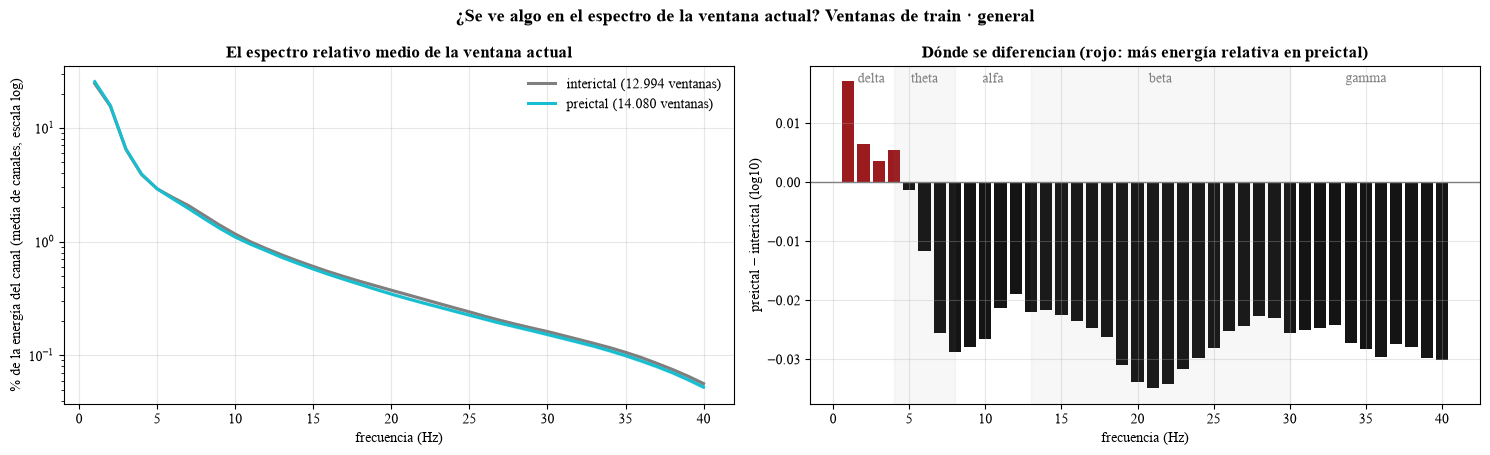

In [11]:
# 1) La ventana actual de cada fila de 🔵 train
en_entrena = filas.en_entrenamiento.to_numpy(dtype=bool)
actual = valores[indices[en_entrena, -1]].reshape(-1, N_CANALES, N_FRECUENCIAS)      # la ventana actual de cada fila de train
y_entrena = y[en_entrena]

# 2) Izquierda: espectro relativo medio de cada clase
with plt.rc_context(ESTILO_TIMES):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.6))
    medias = {}
    for clase, etiqueta in [('interictal', 0), ('preictal', 1)]:
        por_fila = np.nanmean(actual[y_entrena == etiqueta], axis=1)                        # media de los canales
        medias[clase] = np.nanmean(por_fila, axis=0)
        error = 1.96 * np.nanstd(por_fila, axis=0) / np.sqrt(np.sum(~np.isnan(por_fila), axis=0))
        ax1.plot(FRECUENCIAS, 100 * 10 ** medias[clase], color=COLORES_PERIODO[clase], lw=2.2, label=f'{clase} ({numero_legible(int((y_entrena == etiqueta).sum()))} ventanas)')
        ax1.fill_between(FRECUENCIAS, 100 * 10 ** (medias[clase] - error), 100 * 10 ** (medias[clase] + error), color=COLORES_PERIODO[clase], alpha=0.25)
    ax1.set_yscale('log')
    ax1.set_xlabel('frecuencia (Hz)')
    ax1.set_ylabel('% de la energía del canal (media de canales, escala log)')
    ax1.set_title('El espectro relativo medio de la ventana actual', fontsize=12, fontweight='bold')
    ax1.legend(frameon=False)

    # 3) Derecha: dónde se diferencian (preictal − interictal)
    diferencia = medias['preictal'] - medias['interictal']
    ax2.bar(FRECUENCIAS, diferencia, color=np.where(diferencia > 0, COLORES_ESQUEMA['rojo'], COLORES_ESQUEMA['negro']), width=0.8)
    ax2.axhline(0, color='gray', lw=1)
    for banda, (baja, alta) in BANDAS_HZ.items():
        ax2.axvspan(max(baja, FRECUENCIAS[0] - 0.5), min(alta, FRECUENCIAS[-1] + 0.5), color='gray', alpha=0.06 if list(BANDAS_HZ).index(banda) % 2 else 0)
        ax2.text((max(baja, 1) + min(alta, 40)) / 2, 0.98, banda, transform=ax2.get_xaxis_transform(), ha='center', va='top', fontsize=10, color='gray')
    ax2.set_xlabel('frecuencia (Hz)')
    ax2.set_ylabel('preictal − interictal (log10)')
    ax2.set_title('Dónde se diferencian (rojo: más energía relativa en preictal)', fontsize=12, fontweight='bold')

    # 4) Rotular y guardar
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3)
    fig.suptitle(f'¿Se ve algo en el espectro de la ventana actual? Ventanas de train · {CONJUNTO}', fontsize=13, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'espectro_preictal_interictal.png', dpi=150, bbox_inches='tight')
    plt.show()

# 5) Liberar memoria
del actual

👀 **Cómo leer la figura.** A la izquierda, qué % de la energía cae en cada frecuencia, de media (gris = 💤 interictal, azul claro = ⏳ preictal; la banda sombreada es el intervalo del 95 % de la media). A la derecha, la resta ⏳ − 💤 frecuencia a frecuencia, con las bandas clásicas de fondo.

✅ **Qué deberías ver:** dos curvas **casi iguales** (es lo que vio F03.02: la ventana sola, mezclando pacientes, dice poco). Las barras de la derecha son pequeñas; lo que buscará la red es cómo cambian **en el tiempo** y **respecto a lo normal de cada paciente**.

## 5. Cada paciente frente a sí mismo (la calibración de F03.03)

> 🎯 **Qué hacemos:** calcular la calibración de cada paciente con el espectro de la ventana actual, con la normalización que decidió F03.03: su **mediana** (lo normal en él) y su **escala** (lo que suele variar), frecuencia a frecuencia y canal a canal. Al montar cada lote, a **todas las ventanas** de la secuencia se les resta la mediana de su paciente y se dividen por su escala.
>
> 🤔 **Por qué:** las reglas son **exactamente** las de F03.03, con sus mismos nombres (`calibracion_para_red`, en `tfm_comun/prediccion/normalizacion_paciente.py`):
>
> | Normalización | Referencia de cada paciente |
> |---|---|
> | `ninguna` | sin normalizar |
> | `por_paciente` | la mediana de **todas** sus ventanas (sin mirar la etiqueta) |
> | `por_paciente_reserva` | la mediana de sus **primeras 💤 reservadas** (los "minutos tranquilos" de una app); la misma referencia para ⏳ y 💤 |
> | `por_sesion_reserva` | lo mismo, pero por **sesión** (F03.03b): cada grabación con sus primeras 💤 |
>
> La calibración antigua, que comparaba las 💤 con la otra mitad de las 💤 y las ⏳ con todas las 💤, **ya no se acepta**: la referencia dependía de la etiqueta (fuga).

![Cada paciente frente a sí mismo](img/normalizacion_paciente.png)

👀 **Qué enseña.** (La imagen de F03.03.) Dos pacientes con niveles distintos: restada la mediana de cada uno, un mismo umbral sirve para los dos.


<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NORMALIZACION</code> · normalización por paciente que hereda la red (F03.03) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_CANALES</code> · canales de la señal (22) <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">dispositivo</code> · dónde se entrena: la GPU si la hay, si no la CPU <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · ventanas del estudio (las de F03.03, con contexto completo) <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">indices</code> · qué ventanas forman cada secuencia <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">valores</code> · espectro de cada ventana de 4 s (de F03.02/F03.03) <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · etiqueta de cada ventana (1 = ⏳ preictal) <i style="color:#4d4d4d">(§3)</i></li></ul></div>

In [ ]:
# 1) La calibración de cada paciente (mediana y escala de su espectro), con las reglas y nombres de F03.03.
#    Se calcula con TODAS las filas con contexto completo (como F03.03) y luego se queda con las que se usan
grupo_todas, medianas, escalas = calibracion_para_red(valores[indices_todas[:, -1]], grupos_todas, NORMALIZACION, reservada_todas)
grupo = grupo_todas[usar]
assert (grupo >= 0).all(), '🔴 Hay filas sin calibración: revisa la reserva (§3).'

# 2) Las secuencias que verá la red (en la GPU si caben)
datos = SecuenciasEspectro(valores, indices, y, grupo, medianas, escalas, N_CANALES, dispositivo)

# 3) Tabla de la calibración
REFERENCIAS = {'ninguna': 'sin normalizar', 'por_paciente': 'todas las ventanas del paciente', 'por_paciente_reserva': 'sus 💤 reservadas', 'por_sesion_reserva': 'las primeras 💤 de cada sesión'}
tabla_calibracion = pd.DataFrame({
    'normalización': [NORMALIZACION], 'referencia': [REFERENCIAS[NORMALIZACION]], 'pacientes': [len(set(pacientes))],
    'calibraciones distintas': [len(medianas)],
    'espectros en': ['GPU' if datos.en_dispositivo and dispositivo.type != 'cpu' else 'memoria del ordenador'],
    'GB (float16)': [datos.gb]}, index=[CONJUNTO])
tabla_calibracion.index.name = 'conjunto'
display(con_separadores(tabla_calibracion, decimales=2))


👀 **Cómo leer la tabla.** Con qué normalización se trabaja (la de F03.03), cuántos pacientes y cuántas calibraciones distintas hay (una por paciente, o por sesión con `por_sesion_reserva`; una sola si no se normaliza) y dónde se guardan los espectros: si caben, **en la GPU**, y cada lote se monta allí directamente.

Así se ve, de media, lo que recibe la red: la secuencia de la red ya normalizada como decidió F03.03, ⏳ menos 💤 (en 🔵 train):

✅ **Qué deberías ver:** la normalización de F03.03, todos los pacientes con su calibración y, si hay GPU, los espectros en la GPU; en la figura, diferencias ⏳ − 💤 pequeñas y repartidas.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTO_S</code> · segundos de contexto que ve la red (F03.03) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">FRECUENCIAS</code> · frecuencias del espectro que entran a la red <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">K_RED</code> · ventanas de 4 s de cada secuencia <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_FRECUENCIAS</code> · cuántas frecuencias entran a la red <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_FIGURAS</code> · carpeta <code>figuras/</code> dentro de la de salida <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">VENTANA_S</code> · duración de una ventana (s) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">en_entrena</code> · qué ventanas se usan para entrenar <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · etiqueta de cada ventana (1 = ⏳ preictal) <i style="color:#4d4d4d">(§3)</i></li></ul></div>

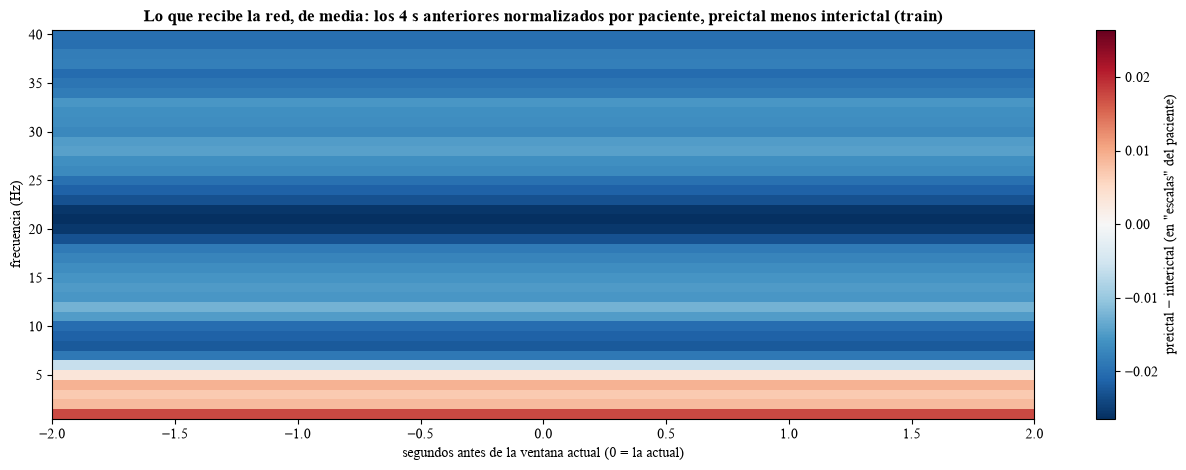

In [13]:
# 1) La media de lo que recibe la red, en cada clase (por trozos de 2.048 filas)
pos_entrena = np.where(en_entrena)[0]
suma = {0: np.zeros((K_RED, N_FRECUENCIAS)), 1: np.zeros((K_RED, N_FRECUENCIAS))}
for a in range(0, len(pos_entrena), 2048):
    x, yy = datos.lote(pos_entrena[a:a + 2048])
    media_canales = x.mean(dim=2).cpu().numpy()                          # (lote, k, frecuencias)
    yy = yy.cpu().numpy()
    for e in (0, 1):
        suma[e] += media_canales[yy == e].sum(axis=0)

# 2) Preictal menos interictal, segundo a segundo y frecuencia a frecuencia
diferencia_secuencia = suma[1] / max((y[en_entrena] == 1).sum(), 1) - suma[0] / max((y[en_entrena] == 0).sum(), 1)
segundos = -VENTANA_S * np.arange(K_RED - 1, -1, -1)
limite = np.nanmax(np.abs(diferencia_secuencia)) or 1

# 3) Dibujar
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(13, 4.8))
    imagen = ax.imshow(diferencia_secuencia.T, aspect='auto', origin='lower', cmap='RdBu_r', vmin=-limite, vmax=limite,
                       extent=[segundos[0] - VENTANA_S / 2, segundos[-1] + VENTANA_S / 2, FRECUENCIAS[0] - 0.5, FRECUENCIAS[-1] + 0.5])
    plt.colorbar(imagen, ax=ax, label='preictal − interictal (en "escalas" del paciente)')
    ax.set_xlabel('segundos antes de la ventana actual (0 = la actual)')
    ax.set_ylabel('frecuencia (Hz)')
    ax.set_title(f'Lo que recibe la red, de media: los {CONTEXTO_S} s anteriores normalizados por paciente, preictal menos interictal (train)',
                 fontsize=12, fontweight='bold')

    # 4) Guardar
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'entrada_media_red.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Cada columna es una de las ventanas de 4 s de la secuencia (a la derecha, la actual) y cada fila, una frecuencia. El color es cuánto se aparta, de media, la ⏳ de la 💤 **respecto a lo normal en su paciente** (media de los 22 canales): rojo = más energía relativa en ⏳, azul = menos, blanco = igual.

✅ **Qué deberías ver:** colores más intensos que en la figura de §4 (la normalización por paciente hace aflorar diferencias que la media entre pacientes tapaba). Si el patrón es parecido en todas las columnas, lo que cuenta es el **nivel** del minuto; si cambia de izquierda a derecha, hay **tendencia**, que es justo lo que puede aprovechar la GRU.

## 6. La red: una CNN para cada ventana y una GRU para el minuto

> 🎯 **Qué hacemos:** crear la red y comprobar que un lote pasa por ella con las formas esperadas.
>
> 🤔 **Por qué esta arquitectura:** la CNN es el punto de partida estándar para resumir el EEG (aprende filtros parecidos a bandas); la GRU es la forma más sencilla y estable de leer una secuencia corta (15 pasos) con pocos pacientes. LSTM, Transformer y la red de grafos de Tang et al. quedan como variantes para comparar después: cambiar la GRU por otra cosa es tocar una sola pieza (`tfm_comun/red/redes/cnn_gru.py`).

![La red](img/arquitectura_cnn_gru.png)

👀 **Qué enseña.** Arriba, las 15 ventanas del último minuto (a la derecha, la actual), ya normalizadas por paciente. Cada una pasa por **la misma** CNN, que la resume en 64 números. La GRU lee esos 15 resúmenes en orden y su memoria final pasa por una capa que da la probabilidad de ⏳. La variante **sin contexto** es la misma red con una sola ventana.

![Qué hace la GRU en cada paso](img/gru_por_dentro.png)

👀 **Qué enseña.** Un paso de la GRU por dentro. Entra la memoria de antes y el resumen de la ventana nueva; la **puerta de actualización z** decide cuánto se conserva y cuánto se reescribe. Abajo, cómo se diferencia de la RNN simple y de la LSTM.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_CANALES</code> · canales de la señal (22) <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_FRECUENCIAS</code> · cuántas frecuencias entran a la red <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code> · semilla común (F03.01) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">datos</code> · las secuencias listas para servir lotes a la red <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">dispositivo</code> · dónde se entrena: la GPU si la hay, si no la CPU <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · ventanas del estudio (las de F03.03, con contexto completo) <i style="color:#4d4d4d">(§3)</i></li></ul></div>

In [14]:
# 1) Una red de ejemplo y sus parámetros
fijar_semillas(SEMILLA)
red_ejemplo = crear_red(N_CANALES, N_FRECUENCIAS).to(dispositivo)
parametros = contar_parametros(red_ejemplo)

# 2) Pasar un lote de 8 filas para ver las formas
x, yy = datos.lote(np.arange(min(8, len(filas))))
with torch.no_grad():
    red_ejemplo.eval()
    resumenes = red_ejemplo.resumir_ventanas(x)
    salida = red_ejemplo(x)

# 3) Tabla de formas
formas = pd.DataFrame([
    ('entrada (un lote de 8 filas)', tuple(x.shape), 'filas × ventanas × canales × frecuencias'),
    ('resumen de cada ventana (CNN)', tuple(resumenes.shape), 'filas × ventanas × 64 números'),
    ('salida (logit)', tuple(salida.shape), 'un número por fila; sigmoid(logit) = probabilidad de ⏳'),
], columns=['paso', 'forma', 'qué es']).set_index('paso')
display(formas)

# 4) Tabla de parámetros por pieza
tabla_parametros = pd.DataFrame({'parámetros': parametros}).rename(index={'codificador': 'CNN (codificador de ventana)', 'gru': 'GRU',
                                                                          'final': 'capa final', 'total': 'total'})
tabla_parametros.index.name = 'pieza'
display(con_separadores(tabla_parametros, decimales=0))
del red_ejemplo

,forma,qué es
paso,,
entrada (un lote de 8 filas),"(8, 1, 22, 40)",filas × ventanas × canales × frecuencias
resumen de cada ventana (CNN),"(8, 1, 64)",filas × ventanas × 64 números
salida (logit),"(8,)",un número por fila; sigmoid(logit) = probabili...


,parámetros
pieza,
CNN (codificador de ventana),25.920
GRU,24.960
capa final,65
total,50.945


👀 **Cómo leer las tablas.** Arriba, la forma de los datos en cada paso (con 8 filas de ejemplo). Abajo, cuántos números aprende cada pieza.

✅ **Qué deberías ver:** entrada `(8, K, 22, 40)`, resúmenes `(8, K, 64)` y salida `(8,)`, con K = ventanas de la secuencia (15 con 60 s de contexto, 1 con la ventana sola). Unos 50.000 parámetros: pocos para una red, a propósito (hay unos 80 pacientes en 🔵 train).

## 7. Entrenar: tres variantes, tres semillas, parada temprana con pacientes de train

> 🎯 **Qué hacemos:** entrenar cada variante con 3 semillas. Se apartan unos pocos **pacientes de 🔵 train** (`FRACCION_PARADA`, los mismos para todas las variantes y semillas): la red aprende con el resto y, al final de cada época, se mide con esos pacientes apartados; se queda la **mejor época**. 🟡 dev **no se mira** hasta que la red está entrenada. Se guardan los pesos de cada red en `modelos/`.
>
> 🤔 **Por qué no parar con 🟡 dev:** si se elige la época en la que la AUC de dev es máxima, y esa curva es ruidosa, el máximo es en parte suerte y la AUC que se publica sale optimista (y además es la que se compara con XGBoost). Con los pacientes apartados de train, la nota de dev es limpia. El precio: la red aprende con algo menos de pacientes.
>
> 🤔 **Por qué tres semillas:** con otra semilla la misma red puede salir ±0,02 de AUC. Promediando las 3 (un **conjunto** o *ensemble* de 3 redes) la nota es más estable, y la tabla enseña cuánto varía.

![Un paso de entrenamiento](img/un_paso_de_entrenamiento.png)

*Arriba: los 7 pasos que se repiten con cada lote (`tfm_comun/red/entreno/entrenar_red.py`). Abajo: cuándo se para.*

![Parada temprana](img/parada_temprana.png)

👀 **Qué enseña.** Cómo se ve un entrenamiento: la pérdida de train (negro) baja siempre; la AUC de validación (rojo; aquí, la de los pacientes apartados de train) sube, se estanca y baja cuando la red empieza a aprenderse a los pacientes con los que aprende. Se guarda la red del punto rojo y se para tras 6 épocas sin mejorar.

> 💡 Con GPU, cada entrenamiento tarda del orden de **1-3 minutos** (los espectros ya están en la tarjeta). En el procesador, bastante más.


<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§0:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§2:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">AJUSTES</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NORMALIZACION</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_SEMILLAS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_MODELOS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">VARIANTES</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">dispositivo</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§3:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">rondas</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§4:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">FRECUENCIAS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_CANALES</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_FRECUENCIAS</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§5:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">datos</code></li></ul></div>

In [ ]:
# 1) En cada ronda, los pacientes de train que se apartan para la parada temprana (los mismos para todas las variantes y semillas)
partes_parada, filas_parada = {}, {}
for ronda, entrena, valida in rondas:
    aprender, parar, apartados = separar_parada(np.where(entrena)[0], pacientes, y, FRACCION_PARADA, SEMILLA)
    con_dev = len(parar) == 0
    if con_dev:                                                       # sin pacientes que apartar: la parada antigua, con validación
        parar = np.where(valida)[0]
    partes_parada[ronda] = (aprender, parar)
    filas_parada[ronda] = {'pacientes para aprender': len(set(pacientes[aprender])), 'pacientes para parar': len(set(pacientes[parar])),
                           'ventanas para aprender': len(aprender), 'ventanas para parar': len(parar),
                           'se para con': '🔴 la validación (optimista)' if con_dev else 'pacientes apartados de 🔵 train'}
display(con_separadores(pd.DataFrame(filas_parada).T.rename_axis('ronda'), decimales=0))

# 2) Entrenar cada variante × semilla × ronda y guardar el modelo
puntuaciones_semilla, historiales, resumen_entrenamiento = {}, [], []
inicio_total = time.time()
for nombre, variante in VARIANTES.items():
    P = np.full((N_SEMILLAS, len(filas)), np.nan)
    for s in range(N_SEMILLAS):
        semilla = SEMILLA + s
        for ronda, entrena, valida in rondas:
            pos_e, pos_p = partes_parada[ronda]
            pos_v = np.where(valida)[0]
            fijar_semillas(semilla)                                    # mismos pesos iniciales con la misma semilla
            red = crear_red(N_CANALES, N_FRECUENCIAS).to(dispositivo)
            pesos = peso_por_paciente(pacientes[pos_e]) if variante['mismo_peso'] else None
            inicio = time.time()
            red, historial, mejor = entrenar_red(red, datos, pos_e, pos_p, k=variante['k'], semilla=semilla, pesos=pesos, ajustes=AJUSTES,
                                                 progreso=lambda it: tqdm(it, desc=f'{nombre} · semilla {semilla} · {ronda}', leave=False))
            P[s, pos_v] = puntuar_red(red, datos, pos_v, k=variante['k'])          # 🟡 dev: solo ahora, con la red ya elegida
            auc_dev = float(roc_auc_score(y[pos_v], P[s, pos_v]))
            ruta_modelo = RUTA_MODELOS / f'{nombre}_semilla{semilla}_{nombre_fichero(ronda)}.pt'
            torch.save({'estado': red.state_dict(), 'arquitectura': ARQUITECTURA, 'k': variante['k'], 'n_canales': N_CANALES,
                        'n_frecuencias': N_FRECUENCIAS, 'frecuencias_hz': FRECUENCIAS.tolist(), 'normalizacion': NORMALIZACION,
                        'mejor_epoca': mejor['epoca'], 'auc_parada': mejor['auc_validacion'], 'auc_validacion': auc_dev,
                        'parada': filas_parada[ronda]['se para con'], 'conjunto': CONJUNTO}, ruta_modelo)
            historiales.append(historial.reset_index().assign(variante=nombre, semilla=semilla, ronda=ronda, medido_con=filas_parada[ronda]['se para con']))
            resumen_entrenamiento.append({'variante': nombre, 'semilla': semilla, 'ronda': ronda, 'mejor época': mejor['epoca'],
                                          'épocas entrenadas': len(historial), 'AUC parada (mejor época)': mejor['auc_validacion'],
                                          'AUC en dev': auc_dev, 'minutos': (time.time() - inicio) / 60})
    puntuaciones_semilla[nombre] = P

# 3) Tabla de los entrenamientos
historial_todo = pd.concat(historiales, ignore_index=True)
tabla_entrenamiento = pd.DataFrame(resumen_entrenamiento).set_index(['variante', 'semilla', 'ronda'])
display(con_separadores(tabla_entrenamiento, decimales=3))
print(f'{len(tabla_entrenamiento)} entrenamientos en {numero_legible(round((time.time() - inicio_total) / 60, 1))} min · '
      f'modelos guardados en {RUTA_MODELOS.relative_to(RUTA_OUTPUTS_FASE_03.parent)}')


👀 **Cómo leer las tablas.** Arriba, cuántos pacientes y ventanas de 🔵 train se usan para aprender y cuántos se apartan para decidir cuándo parar. Abajo, una fila por variante, semilla y ronda: en qué época se quedó la mejor red, cuántas épocas se entrenaron (la mejor + la paciencia, si paró antes del máximo), su AUC con los pacientes de parada (la que decide la época), su AUC en 🟡 dev (medida después, sin elegir nada con ella) y cuánto tardó.

✅ **Qué deberías ver:** AUC parecidas entre semillas de la misma variante (diferencias de 0,01-0,03 son normales). Si la AUC de parada es mucho mayor que la de dev, los pacientes apartados son "fáciles" o la parada sigue siendo ruidosa. Si la mejor época es casi siempre la 1 o la 2, la red se sobreajusta muy deprisa y habría que hacerla más pequeña o con más dropout. Si coincide con el máximo de épocas, aún estaba aprendiendo: habría que subir `epocas_max`.


<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">AUC_XGB</code> · AUC en dev de XGBoost de F03.03 (la referencia) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_FIGURAS</code> · carpeta <code>figuras/</code> dentro de la de salida <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">VARIANTES</code> · las variantes de red que se entrenan <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [ ]:
# 1) Figura: las curvas de aprendizaje de cada variante (una línea por semilla)
variantes = list(VARIANTES)

# 2) Dibujar un panel por variante
with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(1, len(variantes), figsize=(5.4 * len(variantes), 4.6), sharey=False)
    axes = np.atleast_1d(axes)
    for ax, nombre in zip(axes, variantes):
        ax2 = ax.twinx()
        for (semilla, ronda), h in historial_todo[historial_todo.variante == nombre].groupby(['semilla', 'ronda']):
            ax.plot(h['época'], h['pérdida train'], color=COLORES_ESQUEMA['negro'], lw=1.4, alpha=0.8)
            ax.plot(h['época'], h['pérdida validación'], color=COLORES_ESQUEMA['negro'], lw=1.2, ls='--', alpha=0.6)
            ax2.plot(h['época'], h['AUC validación'], color=COLORES_ESQUEMA['rojo'], lw=1.8, alpha=0.85)
            mejor_fila = h.loc[h['AUC validación'].idxmax()]
            ax2.plot(mejor_fila['época'], mejor_fila['AUC validación'], 'o', color=COLORES_ESQUEMA['rojo'], ms=7)
        ax2.axhline(0.5, color=COLORES_ESQUEMA['gris'], ls=':', lw=1.2)      # el azar (la AUC de XGBoost es de dev: no se compara aquí)
        ax.set_xlabel('época')
        ax.set_ylabel('pérdida (negro: aprender continua, parada discontinua)')
        ax2.set_ylabel('AUC de parada (rojo)', color=COLORES_ESQUEMA['rojo'])
        ax.set_title(nombre, fontsize=12, fontweight='bold')
        ax.grid(alpha=0.3)

    # 3) Título y guardar
    fig.suptitle(f'Curvas de aprendizaje: una línea por semilla; el punto rojo es la época que se guarda · {CONJUNTO}', fontsize=13, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'curvas_aprendizaje.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Un panel por variante y una línea por semilla. Negro continuo: la pérdida con la que aprende (eje izquierdo); negro discontinuo: la pérdida con los pacientes de parada. Rojo: la AUC con los pacientes de parada (eje derecho), con un punto en la época que se guarda. La línea gris de puntos es el azar (0,5). La AUC de XGBoost no se dibuja aquí: es de 🟡 dev, y estas curvas no.

✅ **Qué deberías ver:** la pérdida de aprender bajando siempre y la de parada bajando al principio y subiendo después (el **sobreajuste**). Si la pérdida de parada **no baja nunca** y la AUC roja salta arriba y abajo, la red no está aprendiendo nada que sirva para pacientes nuevos. Si las semillas van muy separadas, el resultado depende mucho del azar.


## 8. La nota en dev, ventana a ventana, frente a XGBoost

> 🎯 **Qué hacemos:** juntar las 3 semillas de cada variante (media de sus probabilidades) y medir todas las redes y los modelos de F03.02-F03.03 con **las mismas ventanas** de 🟡 dev y las mismas métricas. Se añade una quinta fila: **red + XGBoost** (la media de sus rangos), por si se complementan.
>
> 🤔 **Por qué ventana a ventana:** F03.03 guardó la puntuación de XGBoost en cada ventana de dev (`puntuaciones_validacion.csv`). Comparar con las mismas ventanas permite la **diferencia emparejada** de §9, mucho más fina que comparar dos intervalos.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ESPECIFICIDAD</code> · especificidad a la que se mide la sensibilidad <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code> · nombre de la referencia XGBoost <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code> · repeticiones del bootstrap por paciente <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">PRINCIPAL</code> · nombre de la variante principal de la red <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code> · semilla común (F03.01) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · ventanas del estudio (las de F03.03, con contexto completo) <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones_semilla</code> · puntuación de cada ventana de dev, por variante y semilla <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">validar</code> · qué ventanas se examinan en 🟡 dev <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · etiqueta de cada ventana (1 = ⏳ preictal) <i style="color:#4d4d4d">(§3)</i></li></ul></div>

In [ ]:
# 1) Las puntuaciones del XGBoost de referencia (F03.03b o F03.03) y de su línea base, solo en las ventanas comunes
puntos_03 = pd.read_csv(RUTA_REFERENCIA / 'puntuaciones_validacion.csv').set_index('id_ventana')
en_03 = filas.id_ventana.isin(puntos_03.index).to_numpy()
comun = validar & en_03
p_xgb, p_base = np.full(len(filas), np.nan), np.full(len(filas), np.nan)
p_xgb[comun] = puntos_03.loc[filas.id_ventana[comun], 'puntuacion_mejor'].to_numpy()
p_base[comun] = puntos_03.loc[filas.id_ventana[comun], 'puntuacion_linea_base_4s'].to_numpy()
print(f'Ventanas de validación con puntuación de {DECISION["origen"]}: {numero_legible(int(comun.sum()))} de {numero_legible(int(validar.sum()))}'
      + ('' if comun.sum() == validar.sum() else ' 🔴 (no son todas: se compara solo con las comunes)'))

# 2) La puntuación de cada red: media de sus semillas
p_red = {}
for nombre, P in puntuaciones_semilla.items():                         # media de las semillas (solo hay puntuación en validación)
    p_red[nombre] = np.full(len(filas), np.nan)
    p_red[nombre][validar] = P[:, validar].mean(axis=0)

# 3) La mezcla red + XGBoost (media de rangos)
def rangos(p):   # de 0 a 1 según el orden; para juntar modelos con escalas distintas
    r = np.full(len(p), np.nan)
    r[comun] = rankdata(p[comun]) / comun.sum()
    return r
MEZCLA = f'red + XGBoost (media de rangos)'
modelos = {'línea base F03.02 (XGBoost, 4 s)': p_base, NOMBRE_XGB: p_xgb, **{f'🧠 {n}': p for n, p in p_red.items()},
           MEZCLA: (rangos(p_red[PRINCIPAL]) + rangos(p_xgb)) / 2}

# 4) La nota de cada modelo
filas_res = {}
for nombre, p in modelos.items():
    auc, inferior, superior = auroc_con_intervalo(y[comun], p[comun], pacientes[comun], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
    pp = auroc_por_paciente(y[comun], p[comun], pacientes[comun])
    variante = nombre.replace('🧠 ', '')
    por_semilla = ([float(auroc_con_intervalo(y[comun], P[comun], pacientes[comun], n_bootstrap=1, semilla=SEMILLA)[0]) for P in puntuaciones_semilla[variante]]
                   if variante in puntuaciones_semilla else [])
    filas_res[nombre] = {'AUC-ROC': auc, 'IC 95 % (por paciente)': f'{decimal(inferior)} – {decimal(superior)}',
                         f'sensibilidad con especificidad {numero_legible(100 * ESPECIFICIDAD)} %': sensibilidad_con_especificidad(y[comun], p[comun], ESPECIFICIDAD)[0],
                         'AUC por paciente (mediana)': float(pp.auroc.median()) if len(pp) else np.nan,
                         'AUC de cada semilla': ' · '.join(decimal(a) for a in por_semilla) if por_semilla else '—',
                         '_inferior': inferior, '_superior': superior}

# 5) Tabla
resultados = pd.DataFrame(filas_res).T.infer_objects()
resultados.index.name = 'modelo'
display(con_separadores(resultados.drop(columns=['_inferior', '_superior']), decimales=3))

👀 **Cómo leer la tabla.** Una fila por modelo, todos medidos con las mismas ventanas de 🟡 dev. Las dos primeras son de F03.02 y F03.03 (su puntuación guardada); las que llevan 🧠 son las redes de este notebook (media de las 3 semillas; la última columna da la AUC de cada semilla por separado); la última, la mezcla de la red principal con XGBoost.

✅ **Qué deberías ver:** la red principal cerca o por encima de XGBoost de F03.03, y por encima de la red de 4 s si el contexto le sirve. Si la mezcla sale por encima de los dos, la red y XGBoost aciertan en ventanas **distintas** y se complementan.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ESPECIFICIDAD</code> · especificidad a la que se mide la sensibilidad <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code> · nombre de la referencia XGBoost <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">PRINCIPAL</code> · nombre de la variante principal de la red <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_FIGURAS</code> · carpeta <code>figuras/</code> dentro de la de salida <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SIN_CONTEXTO</code> · la variante sin contexto (solo la ventana actual) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · etiqueta de cada ventana (1 = ⏳ preictal) <i style="color:#4d4d4d">(§3)</i></li></ul></div>

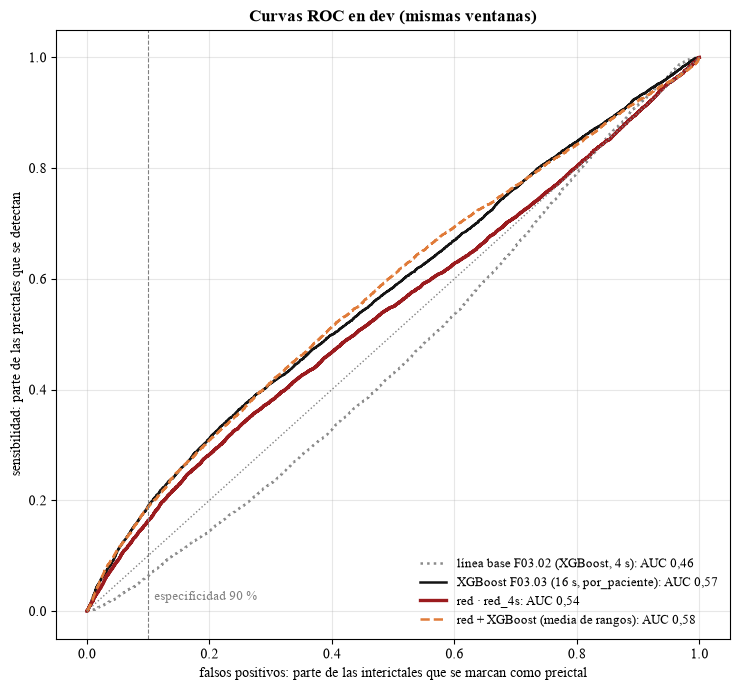

In [18]:
# 1) Figura: curvas ROC de los modelos principales
dibujar = ['línea base F03.02 (XGBoost, 4 s)', NOMBRE_XGB] + [f'🧠 {n}' for n in [PRINCIPAL, SIN_CONTEXTO] if n] + [MEZCLA]
estilos = {dibujar[0]: (COLORES_ESQUEMA['gris'], ':'), dibujar[1]: (COLORES_ESQUEMA['negro'], '-'), f'🧠 {PRINCIPAL}': (COLORES_ESQUEMA['rojo'], '-'),
           MEZCLA: ('#e07b39', '--')}
if SIN_CONTEXTO:
    estilos[f'🧠 {SIN_CONTEXTO}'] = (COLORES_ESQUEMA['rojo'], ':')

# 2) Dibujar
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(7.5, 7))
    for nombre in dibujar:
        fpr, tpr, _ = roc_curve(y[comun], modelos[nombre][comun])
        color, estilo = estilos[nombre]
        ax.plot(fpr, tpr, color=color, ls=estilo, lw=2.4 if 'red_' in nombre and 'mismo' not in nombre and estilo == '-' else 1.8,
                label=f'{nombre.replace("🧠 ", "red · ")}: AUC {decimal(resultados.loc[nombre, "AUC-ROC"])}')
    ax.plot([0, 1], [0, 1], color='gray', lw=1, ls=':')
    ax.axvline(1 - ESPECIFICIDAD, color='gray', lw=0.8, ls='--')
    ax.text(1 - ESPECIFICIDAD + 0.01, 0.02, f'especificidad {numero_legible(100 * ESPECIFICIDAD)} %', color='gray', fontsize=9)

    # 3) Rotular y guardar
    ax.set_xlabel('falsos positivos: parte de las interictales que se marcan como preictal')
    ax.set_ylabel('sensibilidad: parte de las preictales que se detectan')
    ax.set_title('Curvas ROC en dev (mismas ventanas)', fontsize=12, fontweight='bold')
    ax.legend(frameon=False, fontsize=9.5, loc='lower right')
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'curvas_roc_dev.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Cada curva recorre todos los umbrales posibles de un modelo: hacia arriba, más ⏳ detectadas; hacia la derecha, más 💤 marcadas por error. Cuanto más arriba a la izquierda, mejor; la diagonal es el azar. La línea vertical marca el punto de la tabla (especificidad del 90 %). Rojo continuo: la red principal; negro: XGBoost de F03.03.

✅ **Qué deberías ver:** la roja por encima de la negra, sobre todo en la parte izquierda (pocos falsos positivos), que es la que importa para una alarma.

## 9. ¿La red supera a XGBoost? (diferencia emparejada)

> 🎯 **Qué hacemos:** comparar con **diferencia emparejada** (mismas ventanas, mismos sorteos de pacientes): la red principal frente a XGBoost de F03.03, frente al XGBoost que recibió **la misma información** que ella (si no es el mismo), frente a sí misma sin contexto y frente a la variante de mismo peso por paciente; y la mezcla frente a XGBoost.
>
> 🤔 **Por qué:** dos intervalos que se solapan no dicen si una mejora es real; la diferencia emparejada sí (si su intervalo no incluye el 0). Y, como en F03.03, una mejora real menor que `MEJORA_MINIMA` no compensa la complejidad.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§0:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§2:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTO_S</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEJORA_MINIMA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MISMO_PESO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NORMALIZACION</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_SEMILLAS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">PRINCIPAL</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SIN_CONTEXTO</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§3:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§8:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEZCLA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">modelos</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados</code></li></ul></div>

In [ ]:
# 1) Comparar dos modelos, emparejados
def comparar(a, b):
    return diferencia_auroc_con_intervalo(y[comun], modelos[a][comun], modelos[b][comun], pacientes[comun], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)

# 2) Las preguntas que se responden
parejas = [(f'🧠 {PRINCIPAL}', NOMBRE_XGB, 'la red frente a XGBoost (la pregunta principal)')]
if REFERENCIA_JUSTA and REFERENCIA_JUSTA != NOMBRE_XGB:
    parejas.append((f'🧠 {PRINCIPAL}', REFERENCIA_JUSTA, f'la red frente a XGBoost con la MISMA información ({CONTEXTO_S} s, {NORMALIZACION})'))
if SIN_CONTEXTO:
    parejas.append((f'🧠 {PRINCIPAL}', f'🧠 {SIN_CONTEXTO}', f'¿le sirven a la red los {CONTEXTO_S} s?'))
parejas += [(f'🧠 {MISMO_PESO}', f'🧠 {PRINCIPAL}', '¿ayuda dar el mismo peso a cada paciente?'),
            (MEZCLA, NOMBRE_XGB, '¿se complementan la red y XGBoost?')]

# 3) La diferencia de AUC de cada pareja
diferencias = {}
filas_comp = []
for a, b, pregunta in parejas:
    d = comparar(a, b)
    diferencias[(a, b)] = d
    filas_comp.append({'pregunta': pregunta, 'A': a.replace('🧠 ', 'red · '), 'B': b.replace('🧠 ', 'red · '),
                       'diferencia de AUC (A − B)': con_signo(d[0]), 'IC 95 %': f'{decimal(d[1], 3)} – {decimal(d[2], 3)}', 'lectura': lectura_diferencia(d, MEJORA_MINIMA)})
comparacion = pd.DataFrame(filas_comp).set_index('pregunta')

# 4) El veredicto: ¿la red supera a XGBoost?
d_principal = diferencias[(f'🧠 {PRINCIPAL}', NOMBRE_XGB)]
auc_red, inf_red, sup_red = resultados.loc[f'🧠 {PRINCIPAL}', ['AUC-ROC', '_inferior', '_superior']]
if d_principal[1] > 0 and d_principal[0] >= MEJORA_MINIMA:
    veredicto = ('✅ La red supera a XGBoost', 'la red pasa a ser el modelo de referencia de la fase')
elif d_principal[2] < 0:
    veredicto = ('🔴 La red queda por debajo de XGBoost', 'con estos datos, XGBoost con el contexto resumido sigue siendo mejor: antes de complicar la red, revisar §7 (sobreajuste) y probar variantes')
else:
    sentido = 'por encima' if d_principal[0] > 0 else 'por debajo'
    veredicto = ('🟡 Sin diferencia clara con XGBoost',
                 f'la red queda {sentido} ({con_signo(d_principal[0])}), pero el intervalo incluye el 0: con estos pacientes no se puede decir cuál es mejor. '
                 + ('La red llega cerca aprendiendo sola lo que en F03.03 se diseñó a mano; para superarlo hacen falta variantes (más contexto, señal en bruto, grafos)'
                    if MISMA_INFORMACION else
                    f'Ojo: la red recibió menos información que XGBoost ({CONTEXTO_S} s, {NORMALIZACION}), así que no es una comparación de igual a igual'))
d_justa = diferencias.get((f'🧠 {PRINCIPAL}', REFERENCIA_JUSTA)) if REFERENCIA_JUSTA and REFERENCIA_JUSTA != NOMBRE_XGB else None
if d_justa is not None:
    veredicto = (veredicto[0], veredicto[1] + f'. Con la MISMA información, frente a la {REFERENCIA_JUSTA}: {con_signo(d_justa[0])} '
                 f'(IC {decimal(d_justa[1], 3)} – {decimal(d_justa[2], 3)}), {lectura_diferencia(d_justa, MEJORA_MINIMA)}')
elif not MISMA_INFORMACION:
    veredicto = (veredicto[0], veredicto[1] + '. No hay un XGBoost guardado con la misma información para una comparación justa')
if MODO_PRUEBA:
    veredicto = ('🔴 MODO PRUEBA · ' + veredicto[0], veredicto[1] + ' (cifras sin valor: 10 % de las ventanas, 1 semilla, 2 épocas)')

# 5) Mostrarlo destacado
mostrar_destacado(f'{veredicto[0]}',
                  f'Red principal ({CONTEXTO_S} s, {NORMALIZACION}, media de {N_SEMILLAS} semillas): <b>AUC {con_intervalo(auc_red, inf_red, sup_red)}</b> · '
                  f'{NOMBRE_XGB}: <b>{decimal(resultados.loc[NOMBRE_XGB, "AUC-ROC"])}</b> · diferencia <b>{con_signo(d_principal[0])}</b> '
                  f'(IC {decimal(d_principal[1], 3)} – {decimal(d_principal[2], 3)}).', comparacion, f'<b>Qué significa:</b> {veredicto[1]}.')

👀 **Cómo leer el recuadro.** Arriba, el veredicto de la pregunta principal con las dos notas y su diferencia. La tabla responde, con el mismo método, a las cuatro preguntas: cada fila compara A con B; si el intervalo no incluye el 0, la diferencia es real.

✅ **Qué deberías ver:** cuál de las tres situaciones se da (✅ supera, 🟡 empata, 🔴 queda por debajo). **Este veredicto todavía no es el final**: falta el control de sesión (§11), que puede tumbarlo. Si la red recibió menos información que XGBoost (otra normalización u otro contexto), mira también la fila de **misma información**. Un **empate** ya es un resultado útil para la memoria: la red llega sola, desde el espectro, a lo que XGBoost necesitó con un resumen diseñado a mano; y es la base para las variantes siguientes. Si la red con contexto **no** mejora a la de 4 s, la red no está aprovechando el minuto.

## 10. Por paciente y por grupo de crisis

> 🎯 **Qué hacemos:** (1) la AUC **dentro de cada paciente** de 🟡 dev para la red principal y para XGBoost, enfrentadas; (2) la AUC por **grupo de inicio** (⏳ de ese grupo frente a todas las 💤).
>
> 🤔 **Por qué:** una AUC global buena puede venir de unos pocos pacientes muy fáciles. Para una app, importa en **cuántos** pacientes funciona.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code> · repeticiones del bootstrap por paciente <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">PRINCIPAL</code> · nombre de la variante principal de la red <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code> · semilla común (F03.01) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code> · ventanas de dev que tienen nota de todos los modelos <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · ventanas del estudio (las de F03.03, con contexto completo) <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">modelos</code> · la puntuación de cada modelo que se compara <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_xgb</code> · puntuación de XGBoost de F03.03 en cada ventana <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · etiqueta de cada ventana (1 = ⏳ preictal) <i style="color:#4d4d4d">(§3)</i></li></ul></div>

In [ ]:
# 1) AUC dentro de cada paciente con la red y con XGBoost
pp_red = auroc_por_paciente(y[comun], modelos[f'🧠 {PRINCIPAL}'][comun], pacientes[comun])
pp_xgb = auroc_por_paciente(y[comun], p_xgb[comun], pacientes[comun])
por_paciente = pp_red[['auroc', '⏳ preictal', '💤 interictal']].rename(columns={'auroc': 'AUC red'}).join(pp_xgb[['auroc']].rename(columns={'auroc': 'AUC XGBoost'}))
por_paciente['red − XGBoost'] = por_paciente['AUC red'] - por_paciente['AUC XGBoost']
por_paciente = por_paciente.sort_values('AUC red', ascending=False)

# 2) Cuántos pacientes gana la red y cuántos superan el azar
gana_red = int((por_paciente['red − XGBoost'] > 0).sum())
sobre_azar = {m: int((por_paciente[f'AUC {m}'] > 0.5).sum()) for m in ['red', 'XGBoost']}

# 3) AUC por grupo de inicio (con menos de MINIMO_PACIENTES_GRUPO pacientes con ⏳, la cifra es anecdótica)
MINIMO_PACIENTES_GRUPO = 5
grupos = [g for g in ['focal', 'generalizada', 'ausencia'] if g in set(filas.grupo[comun & (y == 1)].dropna())]
filas_grupo = {}
for g in grupos:
    m = comun & ((y == 0) | (filas.grupo.to_numpy() == g))
    fila = {'pacientes con ⏳': len(set(pacientes[m & (y == 1)]))}
    for etiqueta, p in [('red', modelos[f'🧠 {PRINCIPAL}']), ('XGBoost', p_xgb)]:
        a, i_, s_ = auroc_con_intervalo(y[m], p[m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
        fila[f'AUC {etiqueta}'] = a
        fila[f'IC {etiqueta}'] = f'{decimal(i_)} – {decimal(s_)}'
    fila['¿fiable?'] = 'sí' if fila['pacientes con ⏳'] >= MINIMO_PACIENTES_GRUPO else f'⚠️ solo {fila["pacientes con ⏳"]} pacientes: no sacar conclusiones'
    filas_grupo[con_icono(g)] = fila
por_grupo = pd.DataFrame(filas_grupo).T.infer_objects()
por_grupo.index.name = 'grupo de inicio'

# 4) Tabla por grupo
if len(por_grupo):
    display(Markdown('**AUC en dev por grupo de inicio** (⏳ de ese grupo frente a todas las 💤)'))
    display(con_separadores(por_grupo, decimales=3))

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code> · nombre de la referencia XGBoost <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">PRINCIPAL</code> · nombre de la variante principal de la red <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_FIGURAS</code> · carpeta <code>figuras/</code> dentro de la de salida <i style="color:#4d4d4d">(§2)</i></li></ul></div>

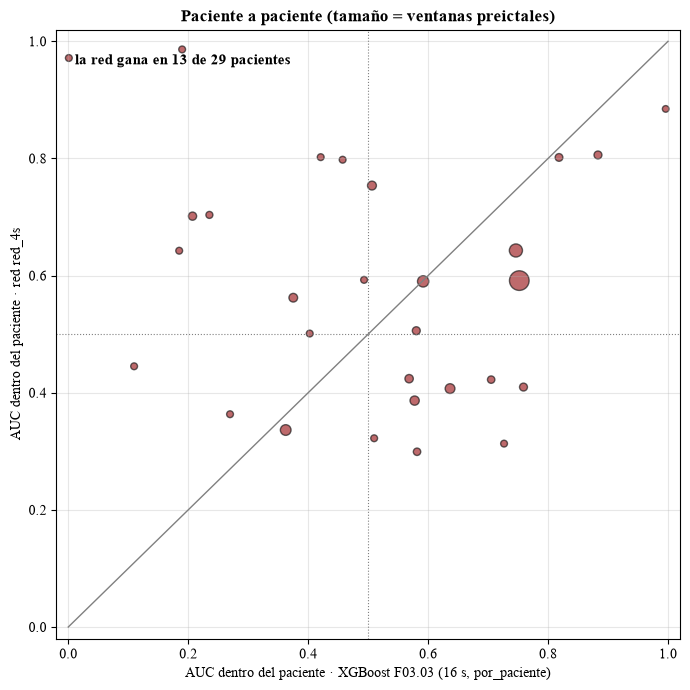

Pacientes de dev con las dos clases: 29 · por encima del azar: red 18, XGBoost 16 · la red gana en 13


In [21]:
# 1) Figura: AUC de cada paciente, red frente a XGBoost
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(7, 7))
    tam = 20 + 180 * por_paciente['⏳ preictal'] / por_paciente['⏳ preictal'].max()
    ax.scatter(por_paciente['AUC XGBoost'], por_paciente['AUC red'], s=tam, color=COLORES_ESQUEMA['rojo'], alpha=0.65, edgecolor=COLORES_ESQUEMA['negro'])
    ax.plot([0, 1], [0, 1], color='gray', lw=1)
    ax.axhline(0.5, color='gray', lw=0.8, ls=':')
    ax.axvline(0.5, color='gray', lw=0.8, ls=':')
    ax.text(0.03, 0.96, f'la red gana en {gana_red} de {len(por_paciente)} pacientes', transform=ax.transAxes, fontsize=11, fontweight='bold', va='top')
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel(f'AUC dentro del paciente · {NOMBRE_XGB}')
    ax.set_ylabel(f'AUC dentro del paciente · red {PRINCIPAL}')
    ax.set_title('Paciente a paciente (tamaño = ventanas preictales)', fontsize=12, fontweight='bold')
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'auc_por_paciente.png', dpi=150, bbox_inches='tight')
    plt.show()

# 2) Resumen en texto
print(f'Pacientes de dev con las dos clases: {len(por_paciente)} · por encima del azar: red {sobre_azar["red"]}, XGBoost {sobre_azar["XGBoost"]} · '
      f'la red gana en {gana_red}')

👀 **Cómo leer la tabla y la figura.** La tabla da la AUC de la red y de XGBoost para cada grupo de inicio, con sus intervalos. En la figura, cada punto es un paciente de 🟡 dev (más grande = más ventanas ⏳): horizontal, su AUC con XGBoost; vertical, con la red. Por encima de la diagonal, la red ordena mejor sus ventanas; las líneas de puntos marcan el azar (0,5).

✅ **Qué deberías ver:** la mayoría de puntos en el cuadrante de arriba a la derecha (los dos por encima del azar) y más por encima de la diagonal que por debajo si la red es mejor. **Cuidado** con los grupos de pocos pacientes (sobre todo 🔹 ausencia): la cifra seria es la del conjunto `grupo_ausencia`, con validación cruzada.

## 11. Control de sesión: ¿predice la crisis o reconoce la grabación?

> 🎯 **Qué hacemos:** repetir la nota en 🟡 dev comparando las ⏳ solo con 💤 de **las mismas sesiones** de su paciente, separando las de **antes** y **después** de una crisis (F03.03b), y con las del mismo fichero (`tfm_comun/prediccion/atajo_grabacion.py: controles_estrictos`). No se reentrena nada. El veredicto usa el **control estricto** (*misma sesión, antes de la crisis*): sin pista de grabación ni de postictal.
>
> 🤔 **Por qué:** una red es mucho más capaz que XGBoost de aprender pistas tramposas. Si la red supera a XGBoost en §9 pero **cae** aquí, su ventaja venía de reconocer la grabación, no de predecir.

![El control de sesión](img/control_sesion_esquema.png)

👀 **Qué enseña.** (La imagen de F03.03.) Un paciente con tres grabaciones; solo la del lunes tiene crisis. El control de *misma sesión* compara sus ⏳ solo con 💤 del lunes.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code> · repeticiones del bootstrap por paciente <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">PRINCIPAL</code> · nombre de la variante principal de la red <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code> · semilla común (F03.01) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_red</code> · AUC de la red principal <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code> · ventanas de dev que tienen nota de todos los modelos <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · ventanas del estudio (las de F03.03, con contexto completo) <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">modelos</code> · la puntuación de cada modelo que se compara <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_xgb</code> · puntuación de XGBoost de F03.03 en cada ventana <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · etiqueta de cada ventana (1 = ⏳ preictal) <i style="color:#4d4d4d">(§3)</i></li></ul></div>

In [ ]:
# 1) Los controles de sesión y la nota de la red y de XGBoost en cada uno
controles = controles_estrictos(comun, y, pacientes, filas.file.to_numpy(), antes)
filas_control, notas_control = {}, {}
for nombre_control, m in controles.items():
    if (y[m] == 0).sum() == 0 or (y[m] == 1).sum() == 0:
        continue
    fila = {'pacientes con las dos clases': len({p for p in set(pacientes[m]) if len(set(y[m & (pacientes == p)])) == 2}),
            '⏳ preictal': int((y[m] == 1).sum()), '💤 interictal': int((y[m] == 0).sum())}
    for etiqueta, p in [('red', modelos[f'🧠 {PRINCIPAL}']), ('XGBoost', p_xgb)]:
        a, i_, s_ = auroc_con_intervalo(y[m], p[m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
        fila[f'AUC {etiqueta}'], fila[f'IC {etiqueta}'] = a, f'{decimal(i_)} – {decimal(s_)}'
        notas_control[(nombre_control, etiqueta)] = (a, i_, s_)
    d = diferencia_auroc_con_intervalo(y[m], modelos[f'🧠 {PRINCIPAL}'][m], p_xgb[m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
    fila['red − XGBoost'], fila['IC de la diferencia'] = con_signo(d[0]), f'{decimal(d[1], 3)} – {decimal(d[2], 3)}'
    notas_control[(nombre_control, 'diferencia')] = d
    filas_control[nombre_control] = fila

# 2) Tabla
control_sesion = pd.DataFrame(filas_control).T.infer_objects()
control_sesion.index.name = 'qué 💤 se usan'

# 3) El veredicto, con el control estricto (o, si no hay bastantes datos, con el de misma sesión)
pacientes_estricto = filas_control.get(CONTROL_ESTRICTO, {}).get('pacientes con las dos clases', 0)
CLAVE_SESION = CONTROL_ESTRICTO if pacientes_estricto >= 5 else 'misma sesión'
if (CLAVE_SESION, 'red') in notas_control:
    auc_ses, inf_ses, _ = notas_control[(CLAVE_SESION, 'red')]
    if inf_red <= 0.5 and inf_ses <= 0.5:
        veredicto_sesion = ('🔴 La red no supera el azar, ni con todas las 💤 ni sin la pista',
                            f'Con todas las 💤 da <b>AUC {decimal(auc_red)}</b> y con el control «{CLAVE_SESION}», <b>AUC {decimal(auc_ses)}</b>: '
                            'los dos intervalos incluyen el azar. No es que reconozca la grabación: no ha aprendido a separar ⏳ de 💤.')
    elif inf_ses > 0.5 and auc_ses >= auc_red - 0.05:
        veredicto_sesion = ('✅ Se mantiene: la red predice la crisis, no la grabación',
                            f'Con el control «{CLAVE_SESION}», la red da <b>AUC {decimal(auc_ses)}</b> (con todas las 💤: {decimal(auc_red)}).')
    elif inf_ses > 0.5:
        veredicto_sesion = ('🟡 Se mantiene en parte',
                            f'Con el control «{CLAVE_SESION}» baja a <b>AUC {decimal(auc_ses)}</b> (con todas: {decimal(auc_red)}), aunque sigue por encima del azar: '
                            'parte de lo que aprende es la grabación.')
    else:
        _, _, sup_ses = notas_control[(CLAVE_SESION, 'red')]
        veredicto_sesion = ('🔴 No se mantiene: la red reconoce la grabación',
                            f'Con el control «{CLAVE_SESION}» cae a <b>AUC {decimal(auc_ses)}</b> '
                            + ('(IC entero <b>por debajo del azar</b>: dentro de la misma grabación ordena al revés).' if sup_ses < 0.5 else
                               '(su intervalo incluye el azar).'))
else:
    veredicto_sesion = ('— Sin control de sesión', 'No hay ⏳ y 💤 de las mismas sesiones en dev.')

# 4) El veredicto FINAL de la red: el de §9 solo vale si el control de sesión lo respalda
if veredicto_sesion[0].startswith('🔴 La red no supera'):
    veredicto_final = ('🔴 La red no predice la crisis', re.sub('<[^>]+>', '', veredicto_sesion[1]).rstrip('.'))
elif veredicto_sesion[0].startswith('🔴'):
    veredicto_final = ('🔴 La red no predice la crisis: reconoce la grabación',
                       f'con todas las 💤 la AUC es {decimal(auc_red)} ({veredicto[0]}), pero con el control «{CLAVE_SESION}» cae a '
                       f'{decimal(notas_control[(CLAVE_SESION, "red")][0])}: lo que separa ⏳ de 💤 es la grabación, no la cercanía de la crisis')
elif veredicto_sesion[0].startswith('🟡') and not veredicto[0].startswith('🔴'):
    veredicto_final = (veredicto[0] + ' (🟡 en parte por la grabación)', veredicto[1] + '. Pero el control de sesión baja bastante la nota: parte de lo que aprende es la grabación')
else:
    veredicto_final = veredicto

# 5) Mostrarlo destacado
mostrar_destacado(f'Control de sesión: {veredicto_sesion[0]}', veredicto_sesion[1], control_sesion,
                  f'<b>Veredicto final de la red (§9 + §11): {veredicto_final[0]}.</b> {veredicto_final[1][0].upper() + veredicto_final[1][1:]}.')

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code> · nombre de la referencia XGBoost <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_FIGURAS</code> · carpeta <code>figuras/</code> dentro de la de salida <i style="color:#4d4d4d">(§2)</i></li></ul></div>

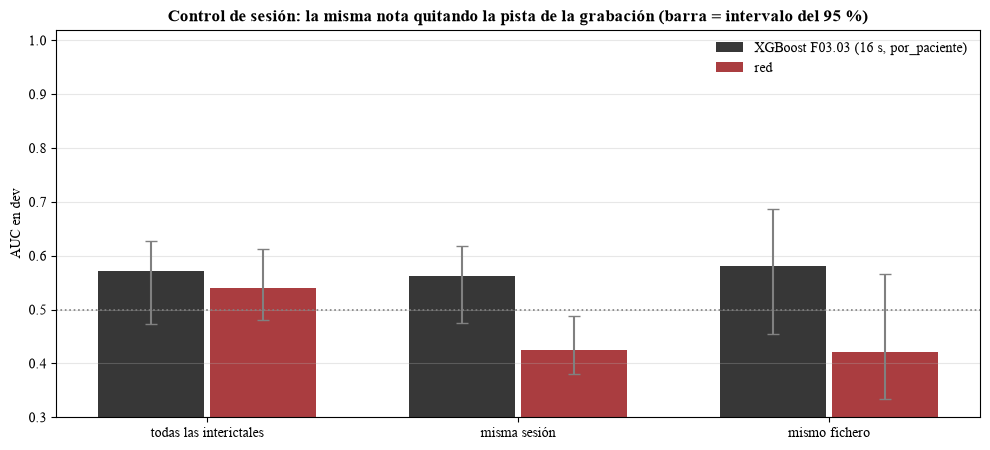

In [23]:
# 1) Figura: la red y XGBoost en cada control
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(10, 4.6))
    nombres_c = list(filas_control)
    x = np.arange(len(nombres_c))
    for desplazamiento, etiqueta, color in [(-0.18, 'XGBoost', COLORES_ESQUEMA['negro']), (0.18, 'red', COLORES_ESQUEMA['rojo'])]:
        a = np.array([notas_control[(c, etiqueta)][0] for c in nombres_c])
        i_ = np.array([notas_control[(c, etiqueta)][1] for c in nombres_c])
        s_ = np.array([notas_control[(c, etiqueta)][2] for c in nombres_c])
        ax.bar(x + desplazamiento, a, width=0.34, color=color, alpha=0.85, label=etiqueta if etiqueta == 'red' else NOMBRE_XGB)
        ax.errorbar(x + desplazamiento, a, yerr=[a - i_, s_ - a], fmt='none', ecolor='gray', capsize=4)

    # 2) Rotular y guardar
    ax.axhline(0.5, color='gray', ls=':', lw=1.2)
    ax.set_xticks(x, [n.replace('💤', 'interictales') for n in nombres_c])
    ax.set_ylim(0.3, 1.02)
    ax.set_ylabel('AUC en dev')
    ax.set_title('Control de sesión: la misma nota quitando la pista de la grabación (barra = intervalo del 95 %)', fontsize=12, fontweight='bold')
    ax.legend(frameon=False)
    ax.grid(alpha=0.3, axis='y')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'control_sesion.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer el recuadro y la figura.** Una fila (y una pareja de barras) por control: con todas las 💤, con las de la misma sesión y con las del mismo fichero. Para cada uno: la AUC de la red y la de XGBoost con sus intervalos, y la diferencia emparejada entre las dos. Arriba, el veredicto con el **control estricto** (*misma sesión, antes de la crisis*; si tiene menos de 5 pacientes, con *misma sesión*):

- ✅ la red sigue cerca de su nota (a menos de 0,05) y por encima del azar: **predice la crisis**;
- 🟡 baja bastante, pero sigue por encima del azar: parte de lo que aprende es la grabación;
- 🔴 cae al azar: la red reconocía la grabación.

Debajo, el **veredicto final**: el de §9 solo se mantiene si este control lo respalda; si la red reconoce la grabación, el veredicto final es 🔴 aunque en §9 empatara o ganara a XGBoost.

✅ **Qué deberías ver:** la barra roja aguantando en el control estricto. Si aguanta en *antes* pero cae en *después de una crisis*, el modelo confunde el postictal con el preictal. En *mismo fichero* es normal que todo baje (control muy duro: muchas 💤 son de después de la crisis).

## 12. El resultado → tablas, puntuaciones y `configuracion.json`

> 🎯 **Qué hacemos:** guardar las tablas, las puntuaciones de dev y `configuracion.json`.
>
> 🤔 **Por qué:** F03.05 parte de aquí: la red, su nota y la comparación con XGBoost.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_RESULTADOS</code> · carpeta de salida de este notebook (en <code>outputs/</code>) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comparacion</code> · las comparaciones de la red con cada referencia <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code> · ventanas de dev que tienen nota de todos los modelos <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">control_sesion</code> · tabla del control de sesión <i style="color:#4d4d4d">(§11)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · ventanas del estudio (las de F03.03, con contexto completo) <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">historial_todo</code> · pérdida y AUC de cada época, de todas las variantes <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_red</code> · puntuación de la red (media de semillas) en cada ventana <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_xgb</code> · puntuación de XGBoost de F03.03 en cada ventana <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">por_paciente</code> · AUC de cada paciente, red y XGBoost <i style="color:#4d4d4d">(§10)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados</code> · AUC en dev de cada modelo <i style="color:#4d4d4d">(§8)</i></li></ul></div>

In [24]:
# 1) Las tablas de resultados, a CSV
(resultados.drop(columns=['_inferior', '_superior'])
    .assign(ic_inferior=resultados._inferior, ic_superior=resultados._superior)
    .reset_index()
    .to_csv(RUTA_RESULTADOS / 'resultados_dev.csv', index=False))
mostrar_fichero(RUTA_RESULTADOS / 'resultados_dev.csv', 'una fila por modelo (redes, XGBoost de F03.03, línea base y la mezcla): AUC en 🟡 dev con las mismas ventanas, '
                'su intervalo, la sensibilidad con especificidad fija, la AUC por paciente y la de cada semilla')
comparacion.reset_index().to_csv(RUTA_RESULTADOS / 'comparacion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'comparacion.csv', 'las diferencias emparejadas de §9 (la red frente a XGBoost, sin contexto, mismo peso y la mezcla)')
historial_todo.to_csv(RUTA_RESULTADOS / 'historial_entrenamiento.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'historial_entrenamiento.csv', 'una fila por época de cada entrenamiento: pérdidas de train y dev, AUC en dev, tasa de aprendizaje y segundos')
por_paciente.reset_index().to_csv(RUTA_RESULTADOS / 'auc_por_paciente.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'auc_por_paciente.csv', 'una fila por paciente de 🟡 dev: AUC dentro del paciente con la red y con XGBoost')
control_sesion.reset_index().to_csv(RUTA_RESULTADOS / 'control_sesion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'control_sesion.csv', 'el control de sesión (§11): AUC de la red y de XGBoost con todas las 💤, las de la misma sesión y las del mismo fichero')

# 2) Las puntuaciones de cada ventana de dev (para comparar en los notebooks siguientes)
puntos = filas.loc[comun, ['id_ventana', 'split', 'patient', 'file', 'clase', 'etiqueta', 'grupo', 'crisis_id']].copy()
for nombre, p in p_red.items():
    puntos[f'puntuacion_{nombre}'] = p[comun].round(5)
puntos['puntuacion_xgboost_f0303'] = p_xgb[comun].round(5)
puntos.to_csv(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', 'una fila por ventana de 🟡 dev: la probabilidad de ⏳ de cada red (media de las semillas) '
                'y la puntuación de XGBoost de F03.03, para comparar ventana a ventana en los notebooks siguientes')

💾 **Guardado `resultados_dev.csv`** · 909 B · 5 filas × 8 columnas  
*Qué guarda:* una fila por modelo (redes, XGBoost de F03.03, línea base y la mezcla): AUC en 🟡 dev con las mismas ventanas, su intervalo, la sensibilidad con especificidad fija, la AUC por paciente y la de cada semilla. *Abajo:* las 5 primeras filas.

,modelo,AUC-ROC,IC 95 % (por paciente),sensibilidad con especificidad 90 %,AUC por paciente (mediana),AUC de cada semilla,ic_inferior,ic_superior
0,"línea base F03.02 (XGBoost, 4 s)",0.459985,"0,42 – 0,51",0.063639,0.512628,—,0.417395,0.508613
1,"XGBoost F03.03 (16 s, por_paciente)",0.571849,"0,47 – 0,63",0.190042,0.510011,—,0.473780,0.627319
2,🧠 red_4s,0.539754,"0,48 – 0,61",0.163464,0.590123,"0,52 · 0,55 · 0,52",0.480299,0.611683
3,🧠 red_4s_mismo_peso,0.560506,"0,50 – 0,63",0.161343,0.588736,"0,55 · 0,57 · 0,54",0.502008,0.627808
4,red + XGBoost (media de rangos),0.576220,"0,49 – 0,63",0.187422,0.540263,—,0.494026,0.634550


💾 **Guardado `comparacion.csv`** · 580 B · 3 filas × 6 columnas  
*Qué guarda:* las diferencias emparejadas de §9 (la red frente a XGBoost, sin contexto, mismo peso y la mezcla). *Abajo:* las 3 primeras filas.

,pregunta,A,B,diferencia de AUC (A − B),IC 95 %,lectura
0,la red frente a XGBoost (la pregunta principal),red · red_4s,"XGBoost F03.03 (16 s, por_paciente)","-0,032","-0,099 – 0,101",sin diferencia clara (el intervalo incluye el 0)
1,¿ayuda dar el mismo peso a cada paciente?,red · red_4s_mismo_peso,red · red_4s,"+0,021","-0,013 – 0,051",sin diferencia clara (el intervalo incluye el 0)
2,¿se complementan la red y XGBoost?,red + XGBoost (media de rangos),"XGBoost F03.03 (16 s, por_paciente)","+0,004","-0,033 – 0,066",sin diferencia clara (el intervalo incluye el 0)


💾 **Guardado `historial_entrenamiento.csv`** · 6,6 KB · 59 filas × 9 columnas  
*Qué guarda:* una fila por época de cada entrenamiento: pérdidas de train y dev, AUC en dev, tasa de aprendizaje y segundos. *Abajo:* las 5 primeras filas.

,época,pérdida train,pérdida validación,AUC validación,tasa de aprendizaje,segundos,variante,semilla,ronda
0,1,0.679829,0.757107,0.497543,0.001,2.270437,red_4s,42,🟡 dev
1,2,0.640782,0.700400,0.510666,0.001,5.223362,red_4s,42,🟡 dev
2,3,0.609708,0.795016,0.501213,0.001,1.810026,red_4s,42,🟡 dev
3,4,0.587036,0.697854,0.526522,0.001,1.438278,red_4s,42,🟡 dev
4,5,0.559844,0.682630,0.483527,0.001,1.531470,red_4s,42,🟡 dev


... (2 outputs left out)

💾 **Guardado `control_sesion.csv`** · 531 B · 3 filas × 10 columnas  
*Qué guarda:* el control de sesión (§11): AUC de la red y de XGBoost con todas las 💤, las de la misma sesión y las del mismo fichero. *Abajo:* las 3 primeras filas.

,qué 💤 se usan,pacientes con las dos clases,⏳ preictal,💤 interictal,AUC red,IC red,AUC XGBoost,IC XGBoost,red − XGBoost,IC de la diferencia
0,todas las 💤,29,8014,41943,0.539754,"0,48 – 0,61",0.571849,"0,47 – 0,63","-0,032","-0,099 – 0,101"
1,misma sesión,25,8014,8402,0.425448,"0,38 – 0,49",0.562695,"0,48 – 0,62","-0,137","-0,213 – -0,031"
2,mismo fichero,18,8014,1234,0.421845,"0,33 – 0,57",0.580958,"0,45 – 0,69","-0,159","-0,318 – 0,079"


💾 **Guardado `puntuaciones_validacion.csv`** · 6,3 MB · 49.957 filas × 11 columnas  
*Qué guarda:* una fila por ventana de 🟡 dev: la probabilidad de ⏳ de cada red (media de las semillas) y la puntuación de XGBoost de F03.03, para comparar ventana a ventana en los notebooks siguientes. *Abajo:* las 5 primeras filas.

,id_ventana,split,patient,file,clase,etiqueta,grupo,crisis_id,puntuacion_red_4s,puntuacion_red_4s_mismo_peso,puntuacion_xgboost_f0303
0,aaaaaajy_s003_t004_interictal_000000000_000030720,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.50096,0.46616,0.55331
1,aaaaaajy_s003_t004_interictal_000000000_000031744,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.39538,0.13219,0.36637
2,aaaaaajy_s003_t004_interictal_000000000_000032768,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.30534,0.22730,0.14383
3,aaaaaajy_s003_t004_interictal_000000000_000033792,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.45581,0.16951,0.18021
4,aaaaaajy_s003_t004_interictal_000000000_000034816,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.46724,0.14421,0.10745


<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§0:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§1:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">versiones_usadas</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§2:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">AJUSTES</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTO_S</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ESPECIFICIDAD</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">K_RED</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEJORA_MINIMA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NORMALIZACION</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_SEMILLAS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">PRINCIPAL</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_MODELOS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_RESULTADOS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SIN_CONTEXTO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SPLITS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">VARIANTES</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ficha</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§4:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">FRECUENCIAS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_CANALES</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§6:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">parametros</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§8:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§9:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_red</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_principal</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">diferencias</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">inf_red</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">sup_red</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§11:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_control</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto_sesion</code></li></ul></div>

In [ ]:
# 1) configuracion.json: la red, sus notas, el veredicto y dónde están los modelos
config = {
    'conjunto': CONJUNTO, 'modo_prueba': MODO_PRUEBA, 'splits_usados': SPLITS, 'eval_usado': False,
    'entrada': {'tipo': 'log10 del espectro relativo por canal (Welch, 1 s)', 'frecuencias_hz': [float(FRECUENCIAS[0]), float(FRECUENCIAS[-1])],
                'canales': N_CANALES, 'contexto_s': CONTEXTO_S, 'ventanas_por_secuencia': K_RED, 'normalizacion': NORMALIZACION},
    'arquitectura': {'tipo': 'CNN por ventana + GRU', **ARQUITECTURA, 'parametros': int(parametros['total'])},
    'entrenamiento': {**AJUSTES, 'n_semillas': N_SEMILLAS, 'semilla_base': SEMILLA, 'fraccion_parada': FRACCION_PARADA,
                      'parada': {r: v['se para con'] for r, v in filas_parada.items()}},
    'ventanas': {'usadas': int(len(filas)), 'reservadas_calibracion': int(reservada_todas.sum()),
                 'otras_apartadas': int(fuera_todas.sum()), 'mismas_que_la_decision': bool(iguales)},
    'decision': {'origen': DECISION['origen'], 'muestreo': MUESTREO, 'montaje_entrenamiento': MONTAJE_E, 'texto': DECISION['texto']},
    'variantes': {n: {'k': v['k'], 'mismo_peso': v['mismo_peso'], 'auc_dev': float(resultados.loc[f'🧠 {n}', 'AUC-ROC'])} for n, v in VARIANTES.items()},
    'principal': {'variante': PRINCIPAL, 'auc_dev': float(auc_red), 'ic95_dev': [float(inf_red), float(sup_red)],
                  'modelos': sorted(str(r.relative_to(RUTA_RESULTADOS)).replace('\\', '/') for r in RUTA_MODELOS.glob(f'{PRINCIPAL}_semilla*.pt'))},
    'frente_a_xgboost': {'auc_xgboost': float(resultados.loc[NOMBRE_XGB, 'AUC-ROC']), 'diferencia': float(d_principal[0]),
                         'ic95_diferencia': [float(d_principal[1]), float(d_principal[2])], 'veredicto': veredicto[0],
                         'misma_informacion': bool(MISMA_INFORMACION)},
    'frente_a_misma_informacion': ({'referencia': REFERENCIA_JUSTA, 'diferencia': float(d_justa[0]), 'ic95_diferencia': [float(d_justa[1]), float(d_justa[2])]}
                                   if d_justa is not None else None),
    'contexto_en_la_red': ({'diferencia_contexto_menos_ventana': float(diferencias[(f'🧠 {PRINCIPAL}', f'🧠 {SIN_CONTEXTO}')][0]),
                            'ic95': [float(v) for v in diferencias[(f'🧠 {PRINCIPAL}', f'🧠 {SIN_CONTEXTO}')][1:]]} if SIN_CONTEXTO else None),
    'veredicto_final': veredicto_final[0],
    'control_sesion': {'veredicto': veredicto_sesion[0],
                       'control': CLAVE_SESION,
                       **({'auc_misma_sesion': float(notas_control[(CLAVE_SESION, 'red')][0])} if (CLAVE_SESION, 'red') in notas_control else {})},
    'ventanas_comparadas': int(comun.sum()), 'especificidad': ESPECIFICIDAD, 'n_bootstrap': N_BOOTSTRAP, 'mejora_minima': MEJORA_MINIMA,
    'dispositivo': ficha['dispositivo'], 'versiones': versiones_usadas, 'fecha': time.strftime('%Y-%m-%d %H:%M'),
}

# 2) Guardar y enseñar
(RUTA_RESULTADOS / 'configuracion.json').write_text(json.dumps(config, indent=4, ensure_ascii=False), encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json', 'la configuración de la red, sus notas, el veredicto frente a XGBoost y dónde están los modelos (lo leerán los notebooks siguientes)')

## 13. Resumen → `summary.txt`

> 🎯 **Qué hacemos:** guardar las cifras principales en `summary.txt`.
>
> 🤔 **Por qué:** para consultarlas sin abrir el notebook.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§0:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§2:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTO_S</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">K_RED</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NORMALIZACION</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_SEMILLAS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_RESULTADOS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§4:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_FRECUENCIAS</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§7:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">tabla_entrenamiento</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§8:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§9:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_red</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comparacion</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_principal</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">inf_red</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">sup_red</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§10:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">por_grupo</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§11:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">control_sesion</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto_sesion</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§12:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">config</code></li></ul></div>

In [ ]:
# 1) Las cifras clave, una por línea
datos_resumen = [
    f'Red neuronal (CNN + GRU): {config["fecha"]} · conjunto {CONJUNTO} · {N_SEMILLAS} semillas desde la {SEMILLA}' + (' · MODO PRUEBA' if MODO_PRUEBA else ''),
    f'Entrada: espectro relativo 22 × {N_FRECUENCIAS} por ventana · {CONTEXTO_S} s de contexto ({K_RED} ventanas) · normalización {NORMALIZACION} · muestreo {MUESTREO} · montaje {MONTAJE_E} (decisión de {DECISION["origen"]})',
    f'{numero_legible(int(comun.sum()))} ventanas de 🟡 dev comparadas con F03.03 · 🟢 eval no usado',
    f'Red principal: AUC {con_intervalo(auc_red, inf_red, sup_red)} · {NOMBRE_XGB}: {decimal(resultados.loc[NOMBRE_XGB, "AUC-ROC"])}',
    f'Frente a XGBoost: {veredicto[0]} ({con_signo(d_principal[0])}; IC {decimal(d_principal[1], 3)} – {decimal(d_principal[2], 3)})',
    f'Control de sesión: {veredicto_sesion[0]}',
    f'VEREDICTO FINAL: {veredicto_final[0]}',
    f'Parada temprana: ' + ' · '.join(f'{r}: {v["se para con"]} ({v["pacientes para parar"]} pacientes)' for r, v in filas_parada.items()),
    f'Ventanas: {numero_legible(len(filas))} usadas · {numero_legible(int(reservada_todas.sum()))} reservadas para calibrar · '
    f'{numero_legible(int(fuera_todas.sum()))} otras apartadas',
]
if d_justa is not None:
    datos_resumen.insert(5, f'Con la misma información ({REFERENCIA_JUSTA}): {con_signo(d_justa[0])} (IC {decimal(d_justa[1], 3)} – {decimal(d_justa[2], 3)})')

# 2) Las tablas
tablas_resumen = {'Resultados en dev': resultados.drop(columns=['_inferior', '_superior']).round(3), 'Comparaciones emparejadas': comparacion,
                  'Entrenamientos': tabla_entrenamiento.round(3), 'Control de sesión': control_sesion.round(3)}
if len(por_grupo):
    tablas_resumen['Por grupo de inicio'] = por_grupo.round(3)

# 3) Escribir y enseñar el summary.txt
texto = ('=== F03.04 · La primera red neuronal ===\n' + '\n'.join(datos_resumen) + '\n\n'
         + '\n\n'.join(f'--- {titulo} ---\n{tabla.to_string()}' for titulo, tabla in tablas_resumen.items()) + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt', 'el resumen de la red en texto')

## 14. Conclusiones

> 🎯 **Qué hacemos:** escribir las conclusiones con los datos de esta ejecución.
>
> 🤔 **Por qué:** si cambian los datos o la red, cambian solas.

Se escriben solas a partir de los datos al ejecutar la celda.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§0:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§2:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTO_S</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEJORA_MINIMA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MISMO_PESO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NORMALIZACION</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_SEMILLAS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">PRINCIPAL</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SIN_CONTEXTO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">VENTANA_S</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§7:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">tabla_entrenamiento</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§8:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEZCLA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§9:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_red</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_principal</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">diferencias</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">inf_red</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">sup_red</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§10:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">gana_red</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">por_paciente</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">sobre_azar</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§11:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto_sesion</code></li></ul></div>

In [ ]:
# 1) La red frente a XGBoost
conclusiones = [
    f'**1. La red frente a XGBoost.** {veredicto[0]}: la red principal ({CONTEXTO_S} s, {NORMALIZACION}) saca **AUC {con_intervalo(auc_red, inf_red, sup_red)}** '
    f'frente a {decimal(resultados.loc[NOMBRE_XGB, "AUC-ROC"])} de XGBoost ({con_signo(d_principal[0])}, IC {decimal(d_principal[1], 3)} – {decimal(d_principal[2], 3)}): {lectura_diferencia(d_principal, MEJORA_MINIMA)}.'
    + ('' if MISMA_INFORMACION else f' Ojo: XGBoost recibió más información que la red ({NOMBRE_XGB}).')
    + (f' Con la misma información (frente a la {REFERENCIA_JUSTA}): {con_signo(d_justa[0])}, IC {decimal(d_justa[1], 3)} – {decimal(d_justa[2], 3)}, '
       f'{lectura_diferencia(d_justa, MEJORA_MINIMA)}.' if d_justa is not None else ''),
]

# 2) El contexto dentro de la red
if SIN_CONTEXTO:
    d_ctx = diferencias[(f'🧠 {PRINCIPAL}', f'🧠 {SIN_CONTEXTO}')]
    conclusiones.append(f'**2. El contexto dentro de la red.** Con {CONTEXTO_S} s la red cambia en {con_signo(d_ctx[0])} respecto a la misma red con solo '
                        f'{VENTANA_S} s (IC {decimal(d_ctx[1], 3)} – {decimal(d_ctx[2], 3)}): {lectura_diferencia(d_ctx, MEJORA_MINIMA)}. '
                        + ('La GRU aprovecha el minuto.' if d_ctx[1] > 0 else 'La red no está sacando partido del contexto.'))

# 3) Mismo peso, mezcla, estabilidad, pacientes y control de sesión
d_peso = diferencias[(f'🧠 {MISMO_PESO}', f'🧠 {PRINCIPAL}')]
conclusiones.append(f'**3. Mismo peso por paciente.** {con_signo(d_peso[0])} (IC {decimal(d_peso[1], 3)} – {decimal(d_peso[2], 3)}): {lectura_diferencia(d_peso, MEJORA_MINIMA)}.')
d_mezcla = diferencias[(MEZCLA, NOMBRE_XGB)]
conclusiones.append(f'**4. Red + XGBoost.** La mezcla cambia la AUC de XGBoost en {con_signo(d_mezcla[0])} (IC {decimal(d_mezcla[1], 3)} – {decimal(d_mezcla[2], 3)}): {lectura_diferencia(d_mezcla, MEJORA_MINIMA)}. '
                    + ('Aciertan en ventanas distintas: se complementan.' if d_mezcla[1] > 0 else 'Aprenden casi lo mismo.'))
auc_semillas = tabla_entrenamiento.xs(PRINCIPAL, level='variante')['AUC en dev']
epocas = tabla_entrenamiento['mejor época']
conclusiones.append(f'**5. Estabilidad.** Las {N_SEMILLAS} semillas de la red principal dan AUC entre {decimal(auc_semillas.min())} y {decimal(auc_semillas.max())} '
                    f'en dev (con la época elegida con los pacientes de parada, no con dev); la mejor época va de la {int(epocas.min())} a la {int(epocas.max())}'
                    + (' (muy pronto: la red se sobreajusta enseguida).' if epocas.median() <= 3 else '.'))
conclusiones.append(f'**6. Paciente a paciente.** La red gana a XGBoost en {gana_red} de {len(por_paciente)} pacientes de dev y queda por encima del azar en {sobre_azar["red"]} '
                    f'(XGBoost: {sobre_azar["XGBoost"]}).')
conclusiones.append(f'**7. Control de sesión: {veredicto_sesion[0]}.** ' + re.sub('<[^>]+>', '', veredicto_sesion[1]))
conclusiones.append(f'**8. Veredicto final: {veredicto_final[0]}.** {veredicto_final[1][0].upper() + veredicto_final[1][1:]}.')

# 4) Mostrar
if MODO_PRUEBA:
    conclusiones.insert(0, '🔴 **MODO PRUEBA:** con un 10 % de las ventanas y 2 épocas, estas cifras no tienen valor.')
display(Markdown('\n\n'.join(conclusiones)))

## 15. Qué nos ha enseñado este notebook (y qué viene después)

> 🎯 **Para qué:** dejar escrito, con los datos de esta ejecución, el razonamiento completo. Es la parte que más se usará en la **memoria**.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTO_S</code> · segundos de contexto que ve la red (F03.03) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code> · nombre de la referencia XGBoost <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SIN_CONTEXTO</code> · la variante sin contexto (solo la ventana actual) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">VENTANA_S</code> · duración de una ventana (s) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_red</code> · AUC de la red principal <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_control</code> · AUC de cada control de sesión <i style="color:#4d4d4d">(§11)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados</code> · AUC en dev de cada modelo <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto</code> · ¿la red supera, iguala o no llega a XGBoost? <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto_sesion</code> · ¿predice la crisis o reconoce la grabación? <i style="color:#4d4d4d">(§11)</i></li></ul></div>

In [ ]:
# 1) Los pasos del estudio, con su AUC y su lectura
pasos_historia = pd.DataFrame([
    ('F03.02 · ventana de 4 s sola (XGBoost)', decimal(resultados.loc[NOMBRE_BASE, 'AUC-ROC']),
     'por debajo del azar' if resultados.loc[NOMBRE_BASE, '_superior'] < 0.5 else 'casi el azar' if resultados.loc[NOMBRE_BASE, '_inferior'] <= 0.5 else 'algo por encima del azar'),
    (f'{DECISION["origen"]} · {NOMBRE_XGB}', decimal(resultados.loc[NOMBRE_XGB, 'AUC-ROC']), f'XGBoost con la decisión de {DECISION["origen"]}'),
    *([(f'F03.04 · red sin contexto ({VENTANA_S} s)', decimal(resultados.loc[f'🧠 {SIN_CONTEXTO}', 'AUC-ROC']), f'la red con la ventana sola · normalización {NORMALIZACION}')]
      if SIN_CONTEXTO else []),
    (f'F03.04 · red con {CONTEXTO_S} s ({NORMALIZACION})', decimal(auc_red), veredicto[0]),
    (f'… con el control «{CLAVE_SESION}»', decimal(notas_control[(CLAVE_SESION, 'red')][0]) if (CLAVE_SESION, 'red') in notas_control else '—', veredicto_sesion[0]),
], columns=['qué se ha probado', 'AUC en 🟡 dev', 'lectura']).set_index('qué se ha probado')

# 2) El siguiente paso, según el veredicto
siguiente = ('mejorar la red: más contexto (si F02.04 lo permite), señal en bruto con una CNN tipo EEGNet, LSTM o Transformer en vez de la GRU, '
             'y la red de grafos de Tang et al.; cada variante, comparada con esta como aquí con XGBoost'
             if not veredicto_final[0].startswith('🔴') else
             ('quitarle a la red la pista de la grabación antes de hacerla más grande: ejecutar F03.03b (el atajo de la grabación), que mide la pista '
              'y decide entrenar solo con 💤 de la misma sesión, y volver a ejecutar este notebook'
              if DECISION['origen'] == 'F03.03' else
              f'la red ya se entrena sin la pista (F03.03b, muestreo {MUESTREO}) y aun así no predice. Si F03.03b dijo que XGBoost sí encuentra señal '
              'con el control estricto, probar F03.05-F03.08 (escalera, clip de 60 s, grafo) midiendo siempre con ese control; si no, valorar con el '
              'tutor predicción por paciente, otro dataset o cerrar la fase con este resultado')
             if veredicto_final[0].startswith('🔴') else
             'antes de probar redes más grandes, entender por qué no llega: curvas de aprendizaje (§7), pacientes donde pierde (§10) y otra '
             'arquitectura más simple; XGBoost sigue siendo la referencia')

# 3) Mostrarlo destacado
mostrar_destacado('Lo que nos ha enseñado F03.04', f'<b>{veredicto_final[0]}.</b> {veredicto_final[1][0].upper() + veredicto_final[1][1:]}.', pasos_historia,
                  f'<b>Siguiente paso (F03.05):</b> {siguiente}. <b>Al final de la fase:</b> la evaluación en continuo y la única pasada por 🟢 eval '
                  '(también por los controles de F02.05).')

👀 **Cómo leer el recuadro.** La historia de la fase en una tabla, con la AUC de cada paso medida con **las mismas ventanas** de 🟡 dev. Debajo, el siguiente paso, que depende del veredicto.

> 📝 **Para la memoria.** La red se puede contar como la continuación natural de F03.03: (1) la ventana sola no basta; (2) el último minuto comparado con lo normal en cada paciente, sí, con un modelo clásico y un resumen hecho a mano; (3) una red que **aprende sola** a resumir el espectro y a leer el minuto en orden, con la misma información, **llega a / supera / no llega a** esa nota (según §9); (4) se comprueba con el control de sesión que no está reconociendo la grabación. Limitación a contar: la época se elige con 🟡 dev, así que su AUC es algo optimista (igual que los hiperparámetros de XGBoost en F03.02); la nota limpia será la de 🟢 eval.

## 16. Archivos generados

En `outputs/fase_03/04_red_prediccion/`:

- `resultados_dev.csv`: la AUC en dev de cada red y de los modelos de F03.02-F03.03, con las mismas ventanas.
- `comparacion.csv`: las diferencias emparejadas de §9.
- `historial_entrenamiento.csv`: cada época de cada entrenamiento (las curvas de aprendizaje).
- `auc_por_paciente.csv` y `control_sesion.csv`: §10 y §11.
- `puntuaciones_validacion.csv`: la probabilidad de cada red en cada ventana de dev (para comparar con las variantes siguientes).
- `modelos/`: los pesos de cada red (`<variante>_semilla<n>_<ronda>.pt`), con su arquitectura y su normalización, listos para la evaluación final y, más adelante, para exportar a ONNX (la demo).
- `configuracion.json` y `summary.txt`.
- `figuras/`: `espectro_preictal_interictal.png`, `entrada_media_red.png`, `curvas_aprendizaje.png`, `curvas_roc_dev.png`, `auc_por_paciente.png`, `control_sesion.png`.
- Los espectros de las ventanas de contexto se guardan en `outputs/fase_03/02_linea_base/caracteristicas/espectro_<CONJUNTO>/` (se reutilizan).

**Para las ausencias:** ejecutar F03.01-F03.03 y este notebook con `CONJUNTO = 'grupo_ausencia'` (contexto más corto y validación cruzada por paciente: una ronda por pliegue).

✅ **Qué deberías ver:** cada paso con su AUC en las mismas ventanas de dev, y el siguiente paso de acuerdo con el veredicto.